# Dravet and CAKUT against the micronutrient gene sets

- Part A - the seed sets and their sizes
- Part B - the pairs ranked, plus the heatmap
- Part C - the colocalized genes per pair, and the genes x gene set heatmap for each disease
- Part D - g:Profiler on the significant pairs
- Part E - colocalized genes as a network, one per disease


## 0. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../scripts")
import ctd_seeds
import geneset_coloc
import micronutrient_coloc as mc
import micronutrient_coloc_figures as mcf

INK, MUTED, GRID = mcf.INK, mcf.MUTED, mcf.GRID

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 120, "font.size": 9,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.width", 220)

FIGURES = mc.OUT / "figures"
TABLES = mc.OUT / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

print(f"networks {mc.NETWORK_OF} | NPS reps {geneset_coloc.NUM_REPS} | "
      f"permutation reps {geneset_coloc.NETCOLOC_NUM_REPS}")

networks {'dravet': 'pcnet22_brain', 'cakut': 'pcnet22_kidney'} | NPS reps 1000 | permutation reps 1000


### Inputs

Each micronutrient set is the union of its CTD genes and the genes of its
primary pathways in `input/micronutrients/micronutrients_pathways.xlsx`, cut to
the HGNC protein-coding genes. The keto diet pathways are in
`input/keto_diet/keto_diet_pathways.xlsx`. The CTD workbook comes from
`ctd_micronutrients.ipynb`, which drops the co-treatment records and cuts each
set by its own reference threshold. The `input/` files are only checked for.

Each disease runs on PCNet 2.2 cut to the genes that its tissue expresses (HPA
nTPM > 1): brain for Dravet, kidney for CAKUT. The seed sets are cut to the same
genes, so the propagation holds only tissue-expressed genes.

In [2]:
import pathway_genes

CTD_WORKBOOK = ctd_seeds.WORKBOOK

SOURCE_FILES = [
    ctd_seeds.ROOT / "input" / "hpa" / "rna_brain_region_hpa.tsv",
    ctd_seeds.ROOT / "input" / "hpa" / "rna_tissue_consensus.tsv",
    *pathway_genes.SELECTIONS,
    pathway_genes.REACTOME_GMT,
    pathway_genes.WIKIPATHWAYS_GMT,
    pathway_genes.HGNC,
    CTD_WORKBOOK,
]

missing = [p for p in SOURCE_FILES if not p.exists()]
if missing:
    raise FileNotFoundError(
        "run ctd_micronutrients.ipynb, or download these first: "
        + ", ".join(str(p) for p in missing)
    )

print(f"CTD workbook found: {CTD_WORKBOOK}")

CTD workbook found: /home/alexandra/dravet/DS-micronutrients/results/ctd/ctd_micronutrient_sets.xlsx


## Part A: the seed sets and their sizes

In [3]:
display(pathway_genes.pathway_summary())

seeds = ctd_seeds.seed_table(keys=mc.MICRONUTRIENTS)
display(seeds)
ctd_seeds.provenance_table(keys=mc.MICRONUTRIENTS).to_csv(
    TABLES / "seed_provenance.tsv", sep="\t", index=False)

print("diseases")
for key in mc.DISEASES:
    mc.use_disease_network(key)
    print(f"  {geneset_coloc.LABELS[key]}: {len(geneset_coloc.seeds_of(key))} genes on the "
          f"{geneset_coloc.NETWORK} node table")

,Micronutrient,Database,Accession,Pathway,n_genes,n_protein_coding
0,Vitamin A,Reactome,R-HSA-975634,Retinoid metabolism and transport,44,44
1,Vitamin A,WikiPathways,WP5188,Retinol metabolism,17,17
2,Vitamin B6,Reactome,R-HSA-964975,Vitamin B6 activation to pyridoxal phosphate,3,3
3,Vitamin B6,KEGG,hsa00750,Vitamin B6 metabolism,6,6
4,Vitamin B12,Reactome,R-HSA-196741,Cobalamin transport and metabolism,22,22
5,Vitamin B12,WikiPathways,WP1533,Vitamin B12 metabolism,55,53
6,Vitamin C,Reactome,R-HSA-196836,Vitamin C (ascorbate) metabolism,8,8
7,Vitamin D,Reactome,R-HSA-196791,Vitamin D (calciferol) metabolism,12,12
8,Vitamin D,WikiPathways,WP1531,Vitamin D metabolism,10,10
9,Vitamin E,Reactome,R-HSA-8877627,Vitamin E transport,1,1


,key,micronutrient,min_references_used,n_ctd,n_pathway,n_ctd_and_pathway,n_genes
0,vita,vitamin A,5,158,59,3,214
1,vitd,vitamin D,3,136,17,6,147
2,vitc,vitamin C,2,54,8,3,59
3,vite,vitamin E,2,73,1,1,73
4,vitb6,vitamin B6,1,25,6,1,30
5,vitb12,vitamin B12,1,20,66,9,77
6,iron,iron,2,27,70,11,86
7,folate,folic acid,2,76,74,15,135
8,zinc,zinc,2,120,15,12,122
9,selenium,selenium,2,33,117,1,149


diseases


  Dravet: 7 genes on the pcnet22_brain node table


CAKUT: 113/132 symbols on the pcnet22_kidney node table, 19 dropped
  CAKUT: 113 genes on the pcnet22_kidney node table


### A1. Seed overlap and seed degree

In [4]:
qc = []
for disease in mc.DISEASES:
    mc.use_disease_network(disease)
    table = geneset_coloc.seed_qc_table([disease] + mc.MICRONUTRIENTS)
    table.index = [geneset_coloc.LABELS.get(k, k) for k in table.index]
    qc.append(table.assign(network=geneset_coloc.NETWORK))
display(pd.concat(qc).round(1))

vitamin A: 197/214 symbols on the pcnet22_brain node table, 17 dropped
vitamin D: 135/147 symbols on the pcnet22_brain node table, 12 dropped
vitamin C: 56/59 symbols on the pcnet22_brain node table, 3 dropped
vitamin E: 70/73 symbols on the pcnet22_brain node table, 3 dropped
vitamin B6: 28/30 symbols on the pcnet22_brain node table, 2 dropped
vitamin B12: 64/77 symbols on the pcnet22_brain node table, 13 dropped
iron: 84/86 symbols on the pcnet22_brain node table, 2 dropped
folic acid: 121/135 symbols on the pcnet22_brain node table, 14 dropped
zinc: 111/122 symbols on the pcnet22_brain node table, 11 dropped
selenium: 147/149 symbols on the pcnet22_brain node table, 2 dropped
keto diet: 37/37 symbols on the pcnet22_brain node table


CAKUT: 113/132 symbols on the pcnet22_kidney node table, 19 dropped
vitamin A: 180/214 symbols on the pcnet22_kidney node table, 34 dropped
vitamin D: 131/147 symbols on the pcnet22_kidney node table, 16 dropped
vitamin C: 54/59 symbols on the pcnet22_kidney node table, 5 dropped
vitamin E: 69/73 symbols on the pcnet22_kidney node table, 4 dropped
vitamin B6: 24/30 symbols on the pcnet22_kidney node table, 6 dropped
vitamin B12: 67/77 symbols on the pcnet22_kidney node table, 10 dropped
iron: 81/86 symbols on the pcnet22_kidney node table, 5 dropped
folic acid: 114/135 symbols on the pcnet22_kidney node table, 21 dropped
zinc: 103/122 symbols on the pcnet22_kidney node table, 19 dropped
selenium: 144/149 symbols on the pcnet22_kidney node table, 5 dropped
keto diet: 32/37 symbols on the pcnet22_kidney node table, 5 dropped


,trait,n_seeds,n_on_lcc,median_seed_degree,network
Dravet,Dravet,7,7,213.0,pcnet22_brain
vitamin A,vitamin A,197,197,414.0,pcnet22_brain
vitamin D,vitamin D,135,135,378.0,pcnet22_brain
vitamin C,vitamin C,56,56,735.0,pcnet22_brain
vitamin E,vitamin E,70,70,632.0,pcnet22_brain
vitamin B6,vitamin B6,28,28,180.5,pcnet22_brain
vitamin B12,vitamin B12,64,64,326.5,pcnet22_brain
iron,iron,84,84,669.5,pcnet22_brain
folic acid,folic acid,121,121,554.0,pcnet22_brain
zinc,zinc,111,111,487.0,pcnet22_brain


In [5]:
import ctd_set_figure as csf

# Seed genes on each tissue network, as counted in n_on_lcc
contents = {}
for disease in mc.DISEASES:
    mc.use_disease_network(disease)
    on_net = set(geneset_coloc.network()[1].tolist())
    contents[disease] = {geneset_coloc.LABELS[k]: {g for g in geneset_coloc.seeds_of(k) if g in on_net}
                         for k in [disease] + mc.MICRONUTRIENTS}

vitamin A: 197/214 symbols on the pcnet22_brain node table, 17 dropped
vitamin D: 135/147 symbols on the pcnet22_brain node table, 12 dropped
vitamin C: 56/59 symbols on the pcnet22_brain node table, 3 dropped
vitamin E: 70/73 symbols on the pcnet22_brain node table, 3 dropped
vitamin B6: 28/30 symbols on the pcnet22_brain node table, 2 dropped
vitamin B12: 64/77 symbols on the pcnet22_brain node table, 13 dropped
iron: 84/86 symbols on the pcnet22_brain node table, 2 dropped
folic acid: 121/135 symbols on the pcnet22_brain node table, 14 dropped
zinc: 111/122 symbols on the pcnet22_brain node table, 11 dropped
selenium: 147/149 symbols on the pcnet22_brain node table, 2 dropped
keto diet: 37/37 symbols on the pcnet22_brain node table


CAKUT: 113/132 symbols on the pcnet22_kidney node table, 19 dropped
vitamin A: 180/214 symbols on the pcnet22_kidney node table, 34 dropped
vitamin D: 131/147 symbols on the pcnet22_kidney node table, 16 dropped
vitamin C: 54/59 symbols on the pcnet22_kidney node table, 5 dropped
vitamin E: 69/73 symbols on the pcnet22_kidney node table, 4 dropped
vitamin B6: 24/30 symbols on the pcnet22_kidney node table, 6 dropped
vitamin B12: 67/77 symbols on the pcnet22_kidney node table, 10 dropped
iron: 81/86 symbols on the pcnet22_kidney node table, 5 dropped
folic acid: 114/135 symbols on the pcnet22_kidney node table, 21 dropped
zinc: 103/122 symbols on the pcnet22_kidney node table, 19 dropped
selenium: 144/149 symbols on the pcnet22_kidney node table, 5 dropped
keto diet: 32/37 symbols on the pcnet22_kidney node table, 5 dropped


Written to /home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/figures/fig_seed_sources.png


Written to /home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/figures/fig_seed_sources.pdf


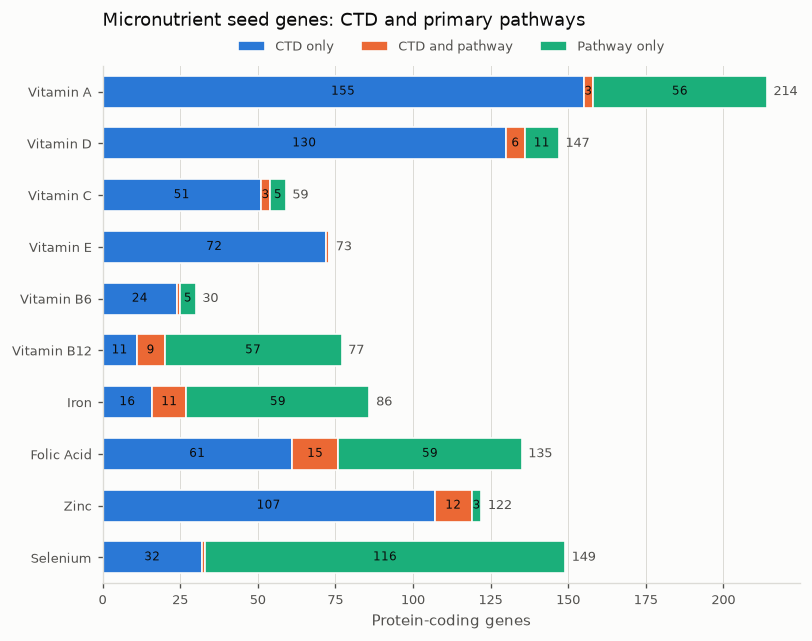

In [6]:
# CTD genes against primary pathway genes for each micronutrient, cut to protein-coding genes.
coding = set(pathway_genes.hgnc_protein_coding()["symbol"])
nutrients = [k for k in mc.MICRONUTRIENTS if k not in ctd_seeds.SYMBOL_FILES
             and ctd_seeds.KEYS[k] in csf.COLORS]
ctd = {ctd_seeds.KEYS[k]: ctd_seeds.ctd_genes(k)[0] & coding for k in nutrients}
pathway = {ctd_seeds.KEYS[k]: ctd_seeds.primary_pathway_genes(k) & coding for k in nutrients}
fig = csf.source_figure(ctd, pathway, output_path=FIGURES / "fig_seed_sources.png",
                        title="Micronutrient seed genes: CTD and primary pathways")
plt.show()

vitamin A: 197/214 symbols on the pcnet22_brain node table, 17 dropped
vitamin D: 135/147 symbols on the pcnet22_brain node table, 12 dropped
vitamin C: 56/59 symbols on the pcnet22_brain node table, 3 dropped
vitamin E: 70/73 symbols on the pcnet22_brain node table, 3 dropped
vitamin B6: 28/30 symbols on the pcnet22_brain node table, 2 dropped
vitamin B12: 64/77 symbols on the pcnet22_brain node table, 13 dropped
iron: 84/86 symbols on the pcnet22_brain node table, 2 dropped
folic acid: 121/135 symbols on the pcnet22_brain node table, 14 dropped
zinc: 111/122 symbols on the pcnet22_brain node table, 11 dropped
selenium: 147/149 symbols on the pcnet22_brain node table, 2 dropped
keto diet: 37/37 symbols on the pcnet22_brain node table


Written to /home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/figures/fig_seed_upset_pcnet22_brain.png


Written to /home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/figures/fig_seed_upset_pcnet22_brain.pdf


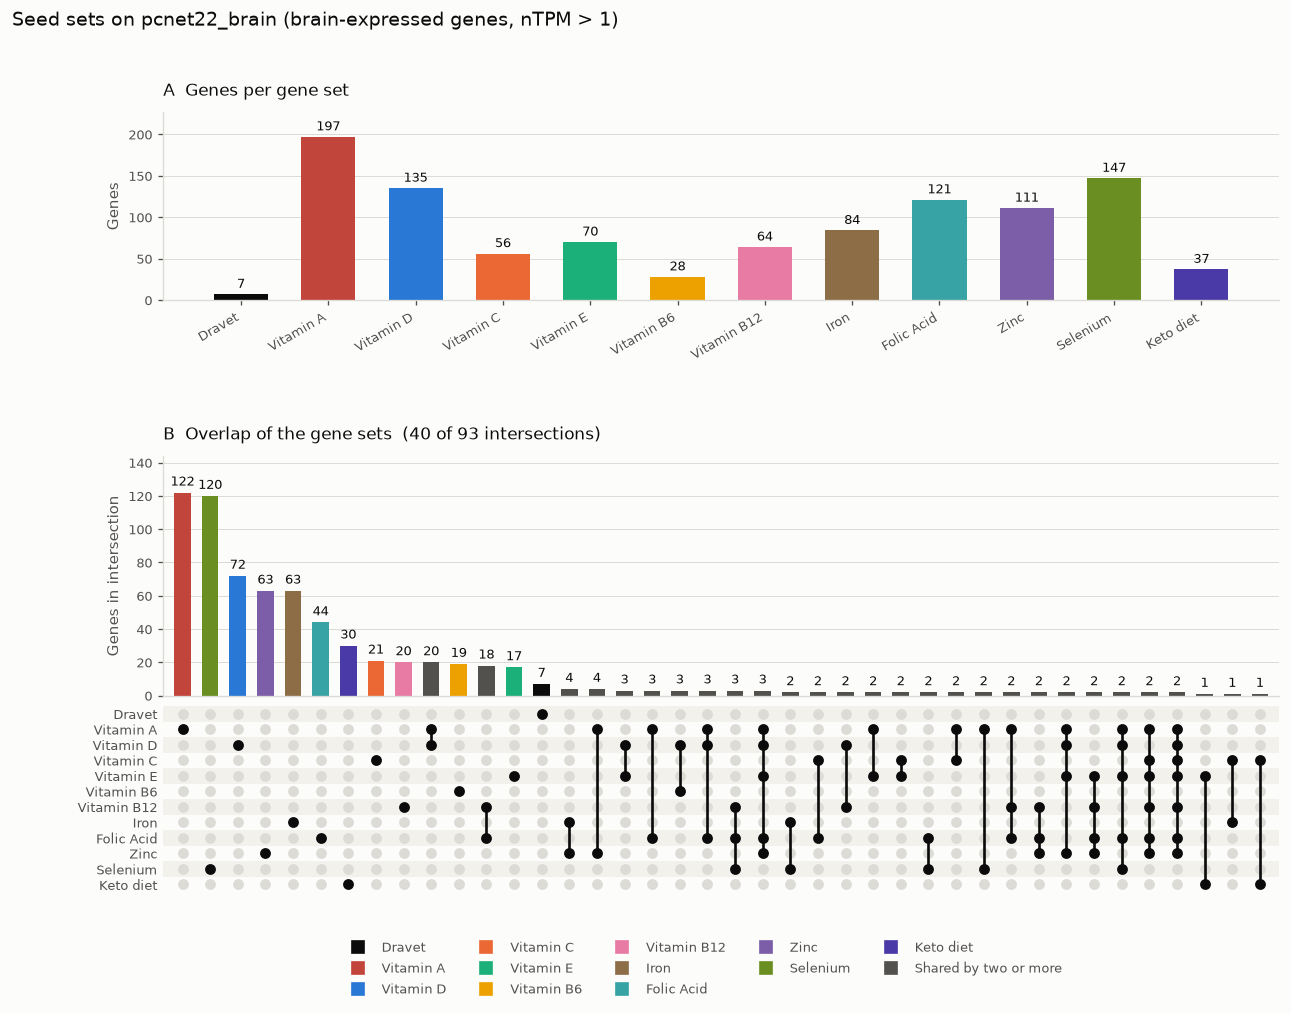

CAKUT: 113/132 symbols on the pcnet22_kidney node table, 19 dropped
vitamin A: 180/214 symbols on the pcnet22_kidney node table, 34 dropped
vitamin D: 131/147 symbols on the pcnet22_kidney node table, 16 dropped
vitamin C: 54/59 symbols on the pcnet22_kidney node table, 5 dropped
vitamin E: 69/73 symbols on the pcnet22_kidney node table, 4 dropped
vitamin B6: 24/30 symbols on the pcnet22_kidney node table, 6 dropped
vitamin B12: 67/77 symbols on the pcnet22_kidney node table, 10 dropped
iron: 81/86 symbols on the pcnet22_kidney node table, 5 dropped
folic acid: 114/135 symbols on the pcnet22_kidney node table, 21 dropped
zinc: 103/122 symbols on the pcnet22_kidney node table, 19 dropped
selenium: 144/149 symbols on the pcnet22_kidney node table, 5 dropped
keto diet: 32/37 symbols on the pcnet22_kidney node table, 5 dropped


Written to /home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/figures/fig_seed_upset_pcnet22_kidney.png


Written to /home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/figures/fig_seed_upset_pcnet22_kidney.pdf


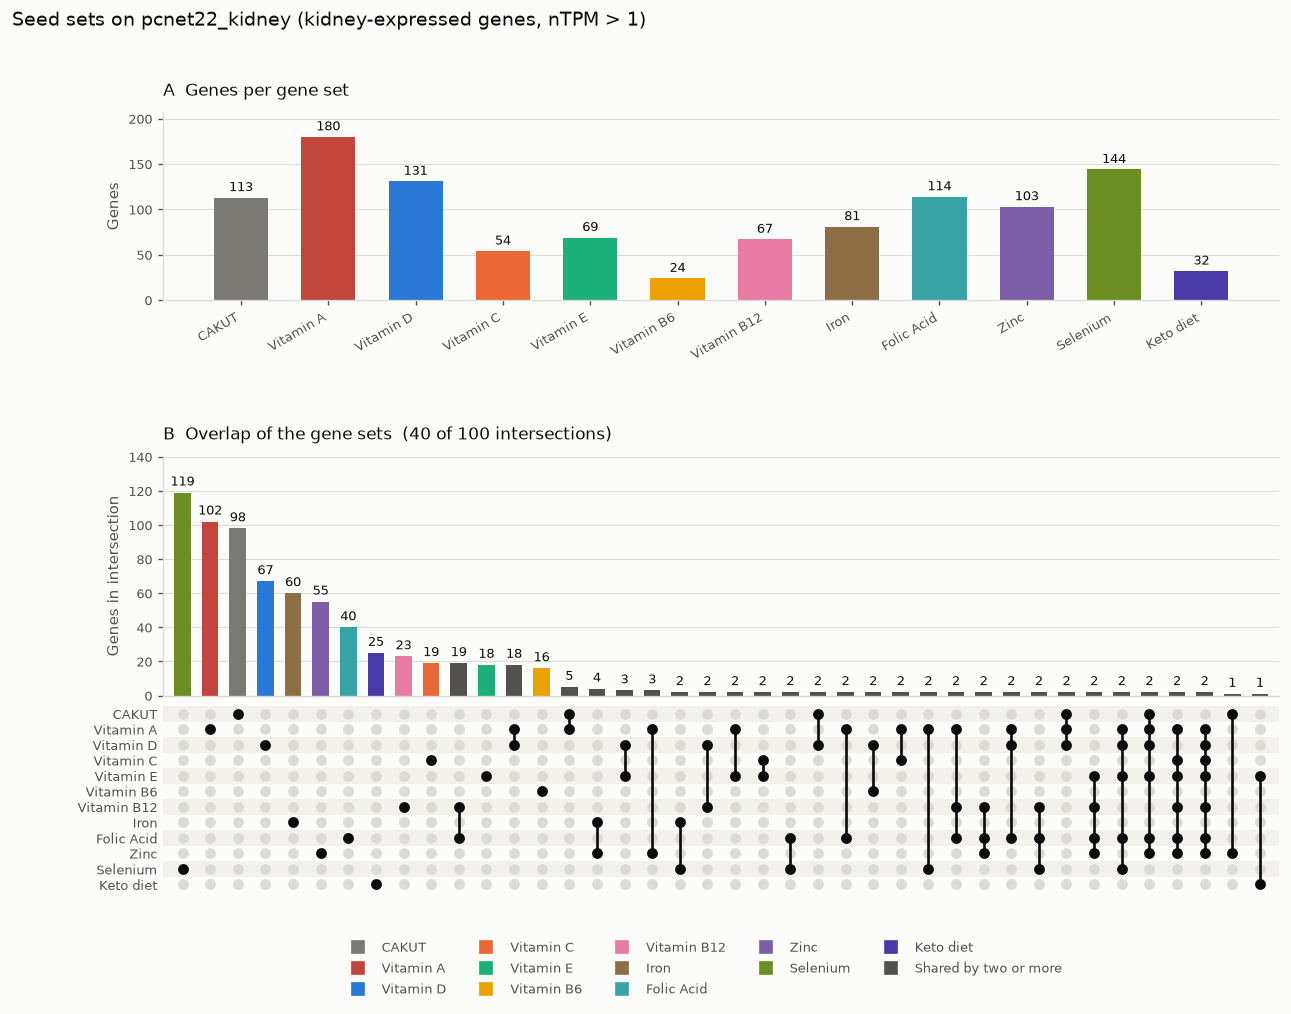

In [7]:
# UpSet plots of the disease and micronutrient seed sets on each tissue network.
names = {**{k: geneset_coloc.LABELS[k] for k in mc.DISEASES}, **{k: ctd_seeds.KEYS[k] for k in mc.MICRONUTRIENTS}}
for disease in mc.DISEASES:
    mc.use_disease_network(disease)
    _, nodes, symbol_of, _ = geneset_coloc.network()
    on_net = set(nodes.tolist())
    all_sets = {names[k]: {symbol_of[g] for g in geneset_coloc.seeds_of(k) if g in on_net}
                for k in [disease] + mc.MICRONUTRIENTS}
    fig = csf.make_figure(all_sets,
                          output_path=FIGURES / f"fig_seed_upset_{geneset_coloc.NETWORK}.png",
                          order=list(all_sets),
                          title=f"Seed sets on {geneset_coloc.NETWORK}",
                          subtitle=f" ({mc.TISSUE_OF[disease]}-expressed genes, nTPM > 1)")
    plt.show()

#### Seed overlap between the micronutrients

The number of seed genes on each tissue network that two micronutrient sets share. The diagonal is the size of each set.


In [8]:
nutrients = [geneset_coloc.LABELS[k] for k in mc.MICRONUTRIENTS]
for disease in mc.DISEASES:
    sets = contents[disease]
    overlap = pd.DataFrame([[len(sets[a] & sets[b]) for b in nutrients]
                            for a in nutrients], index=nutrients, columns=nutrients)
    overlap.to_csv(TABLES / f"seed_overlap_micronutrients_{mc.NETWORK_OF[disease]}.tsv",
                   sep="\t")
    print(mc.NETWORK_OF[disease])
    display(overlap)

pcnet22_brain


,vitamin A,vitamin D,vitamin C,vitamin E,vitamin B6,vitamin B12,iron,folic acid,zinc,selenium,keto diet
vitamin A,197,46,19,31,3,14,9,33,29,13,1
vitamin D,46,135,12,27,5,9,7,24,19,9,2
vitamin C,19,12,56,26,3,9,9,23,22,9,3
vitamin E,31,27,26,70,3,13,9,32,31,14,3
vitamin B6,3,5,3,3,28,1,0,4,2,2,1
vitamin B12,14,9,9,13,1,64,2,38,14,6,0
iron,9,7,9,9,0,2,84,7,13,4,1
folic acid,33,24,23,32,4,38,7,121,31,18,2
zinc,29,19,22,31,2,14,13,31,111,8,2
selenium,13,9,9,14,2,6,4,18,8,147,2


pcnet22_kidney


,vitamin A,vitamin D,vitamin C,vitamin E,vitamin B6,vitamin B12,iron,folic acid,zinc,selenium,keto diet
vitamin A,180,46,20,29,3,14,9,31,28,12,1
vitamin D,46,131,13,26,4,9,7,24,18,9,2
vitamin C,20,13,54,26,3,9,9,22,22,9,3
vitamin E,29,26,26,69,3,13,9,31,30,13,3
vitamin B6,3,4,3,3,24,1,0,4,2,2,1
vitamin B12,14,9,9,13,1,67,2,38,14,5,0
iron,9,7,9,9,0,2,81,7,13,4,1
folic acid,31,24,22,31,4,38,7,114,31,16,2
zinc,28,18,22,30,2,14,13,31,103,8,2
selenium,12,9,9,13,2,5,4,16,8,144,2


## Part B: Ranked pairs

In [9]:
mc.run_pairs_out_of_process()

running dravet vs vita ...


vitamin A: 197/214 symbols on the pcnet22_brain node table, 17 dropped
Overlap seed genes: 0


  2%|▏         | 16/1000 [00:00<00:06, 155.33it/s]

  5%|▍         | 48/1000 [00:00<00:06, 148.29it/s]

  8%|▊         | 78/1000 [00:00<00:06, 135.22it/s]

...

 89%|████████▉ | 890/1000 [00:03<00:00, 296.08it/s]

 95%|█████████▌| 952/1000 [00:03<00:00, 300.09it/s]

100%|██████████| 1000/1000 [00:03<00:00, 295.11it/s]


wrote cakut_keto.pkl coloc 188 z 16.33


PosixPath('/home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/pairs')

In [10]:
results, gene_tables = mc.load_cached()
pair_stats = mc.pair_stats_table(results, out_tsv=TABLES / "pair_stats.tsv")
display(pair_stats[[
    "disease", "micronutrient", "n_micronutrient_seeds", "min_references_used",
    "median_seed_degree", "coloc_size", "mean_combined_z", "z_mean_z",
    "p_mean_z", "q_mean_z", "significant",
]].round(3))

,disease,micronutrient,n_micronutrient_seeds,min_references_used,median_seed_degree,coloc_size,mean_combined_z,z_mean_z,p_mean_z,q_mean_z,significant
0,CAKUT,vitamin A,180,5.0,430.0,737,3.342,62.709,0.000,0.000,True
1,CAKUT,vitamin D,131,3.0,353.0,611,2.522,61.054,0.000,0.000,True
2,CAKUT,vitamin E,69,2.0,619.0,664,2.325,60.854,0.000,0.000,True
3,CAKUT,zinc,103,2.0,483.0,427,1.883,53.090,0.000,0.000,True
4,CAKUT,folic acid,114,2.0,526.5,664,2.189,48.813,0.000,0.000,True
5,CAKUT,vitamin C,54,2.0,636.5,452,1.605,45.193,0.000,0.000,True
6,CAKUT,vitamin B12,67,1.0,287.0,409,1.424,41.999,0.000,0.000,True
7,CAKUT,vitamin B6,24,1.0,158.0,177,0.515,23.076,0.000,0.000,True
8,CAKUT,keto diet,32,NaN,380.5,188,0.411,16.328,0.000,0.000,True
9,CAKUT,iron,81,2.0,670.0,162,0.440,12.915,0.000,0.000,True


### B1. The heatmap

Diseases are the columns and gene sets the rows. Colour is the BH q on a -log10
scale, the number is the module size, and a star marks a significant pair.

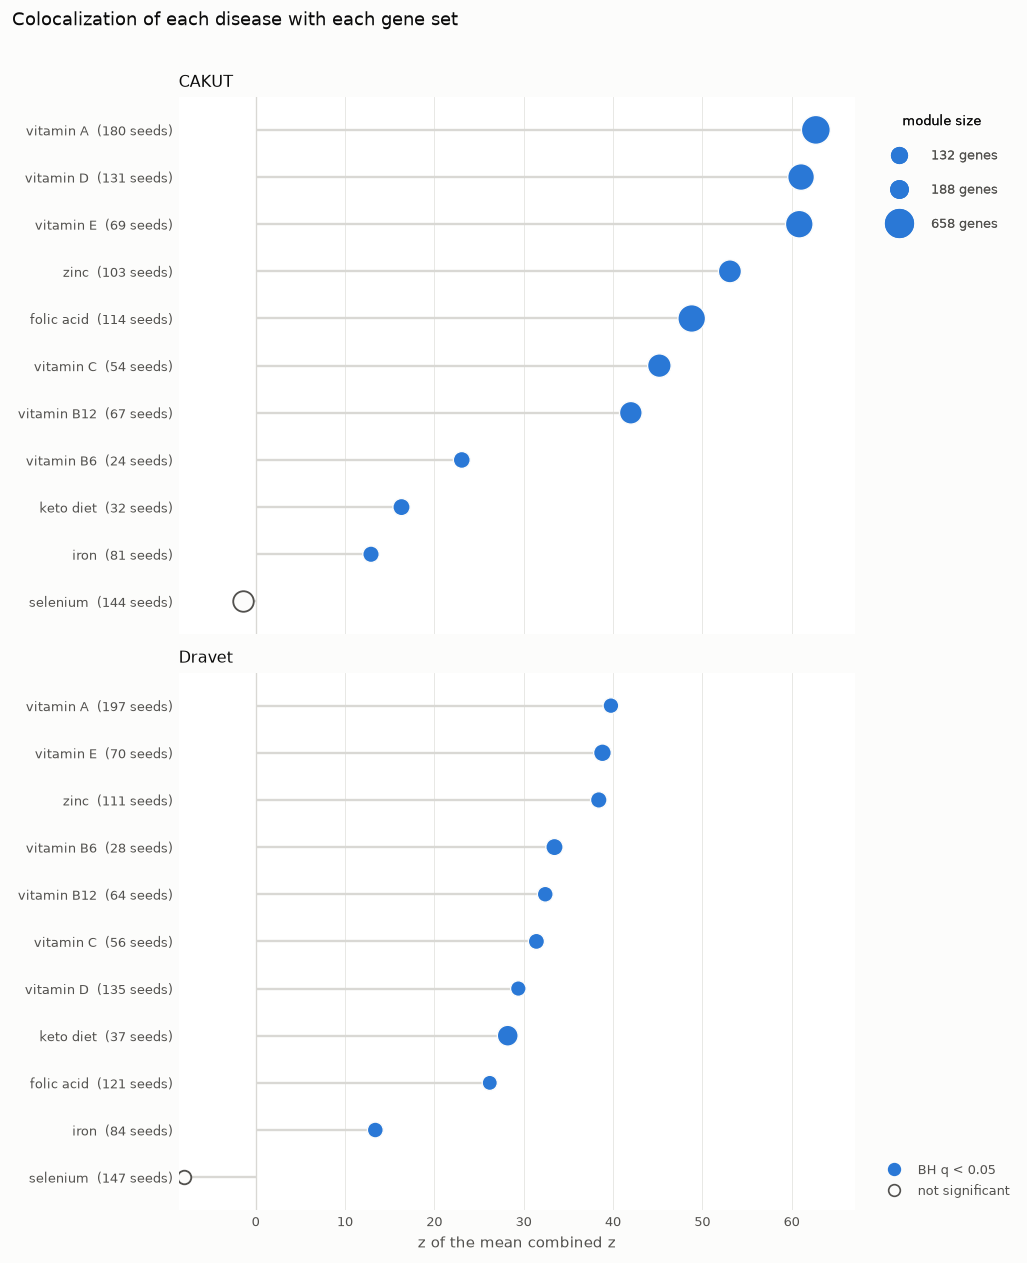

In [11]:
fig = mcf.pair_dotplot(pair_stats, q_thresh=mc.Q_THRESH,
                       out_png=FIGURES / "fig_pair_dotplot.png")
plt.show()

### B2. Shared proximity or shared avoidance

In [12]:
quad = pair_stats[["disease", "micronutrient", "mean_combined_z",
                   "contrib_both_negative", "z_mean_z", "significant"]].copy()
quad["carried_by_avoidance"] = (quad["contrib_both_negative"]
                                > quad["mean_combined_z"])
display(quad.round(3))

,disease,micronutrient,mean_combined_z,contrib_both_negative,z_mean_z,significant,carried_by_avoidance
0,CAKUT,vitamin A,3.342,2.804,62.709,True,False
1,CAKUT,vitamin D,2.522,2.125,61.054,True,False
2,CAKUT,vitamin E,2.325,1.894,60.854,True,False
3,CAKUT,zinc,1.883,1.728,53.090,True,False
4,CAKUT,folic acid,2.189,1.903,48.813,True,False
5,CAKUT,vitamin C,1.605,1.484,45.193,True,False
6,CAKUT,vitamin B12,1.424,1.398,41.999,True,False
7,CAKUT,vitamin B6,0.515,0.745,23.076,True,True
8,CAKUT,keto diet,0.411,0.744,16.328,True,True
9,CAKUT,iron,0.440,0.988,12.915,True,True


## Part C: colocalized genes per pair

A gene is in the colocalized module of a pair when NPS_disease > 1.5,
NPS_micronutrient > 1.5, and NPS_disease x NPS_micronutrient >= 3. The
combined z of a gene is that product.

In [13]:
summary = []
for (disease, nutrient), table in gene_tables.items():
    summary.append({
        "disease": geneset_coloc.LABELS[disease],
        "micronutrient": geneset_coloc.LABELS[nutrient],
        "coloc_genes": len(table),
    })
display(pd.DataFrame(summary).sort_values(["disease", "coloc_genes"],
                                          ascending=[True, False]))

,disease,micronutrient,coloc_genes
11,CAKUT,vitamin A,748
18,CAKUT,folic acid,668
14,CAKUT,vitamin E,667
12,CAKUT,vitamin D,618
13,CAKUT,vitamin C,452
19,CAKUT,zinc,431
16,CAKUT,vitamin B12,409
20,CAKUT,selenium,317
21,CAKUT,keto diet,188
15,CAKUT,vitamin B6,177


### C1. The genes x gene set heatmap

Dravet: 941 genes in at least one module


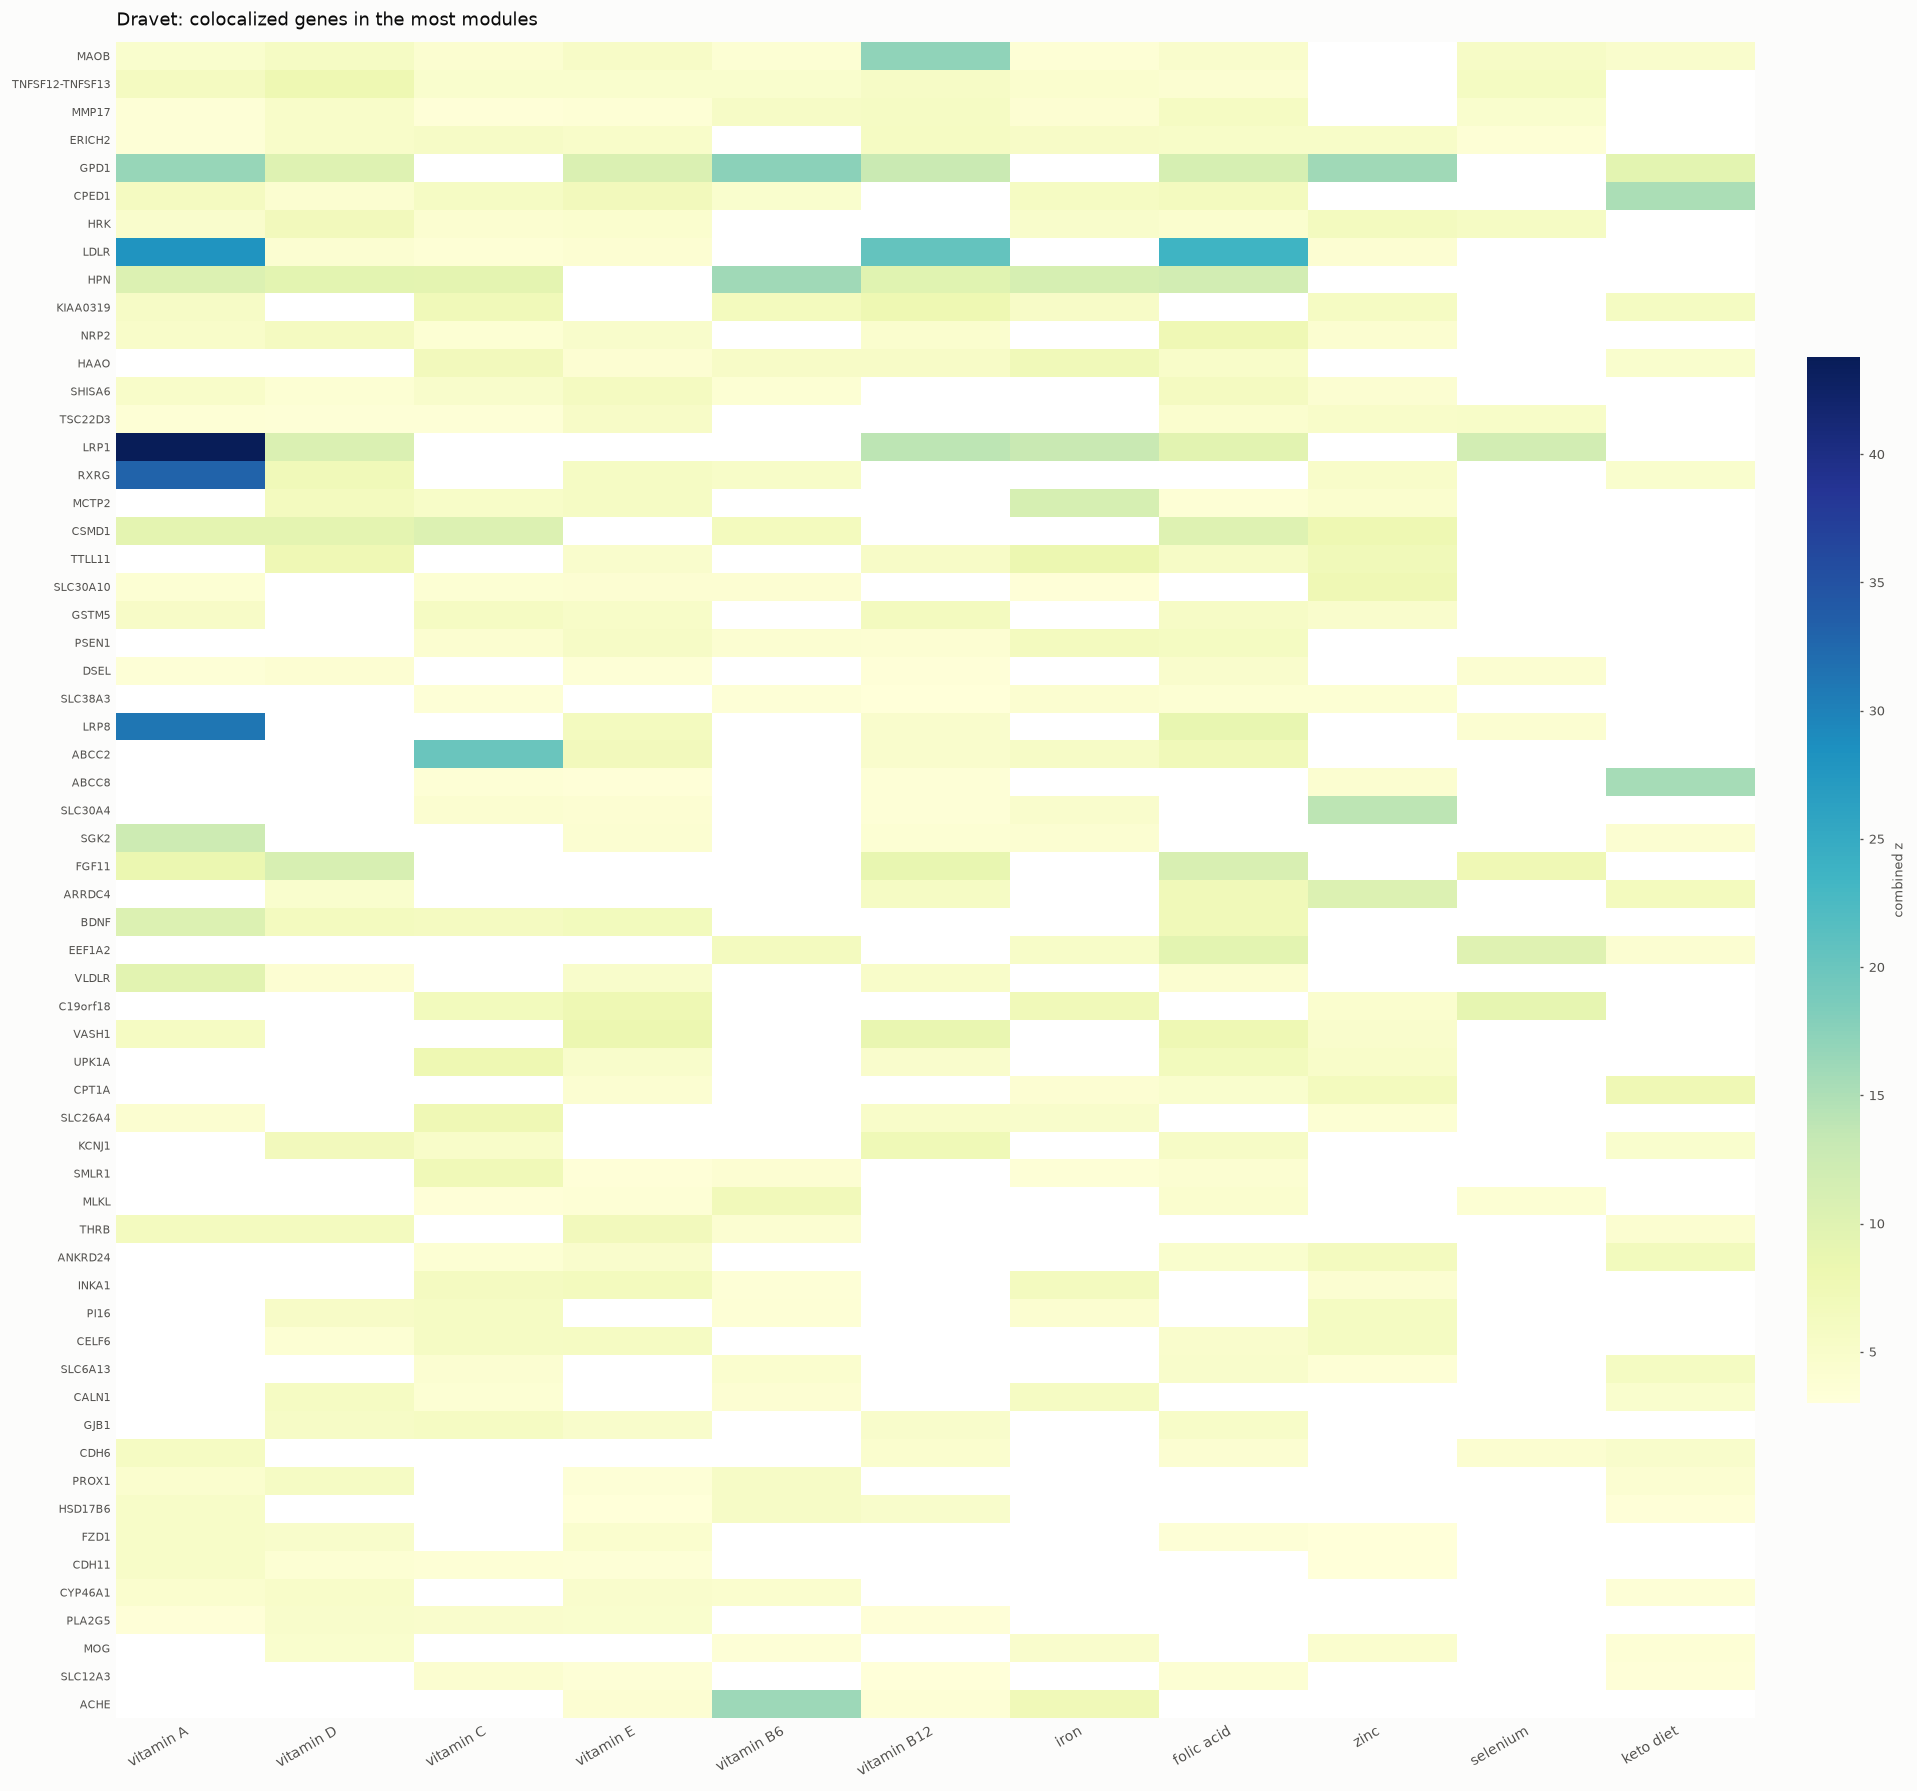

CAKUT: 1303 genes in at least one module


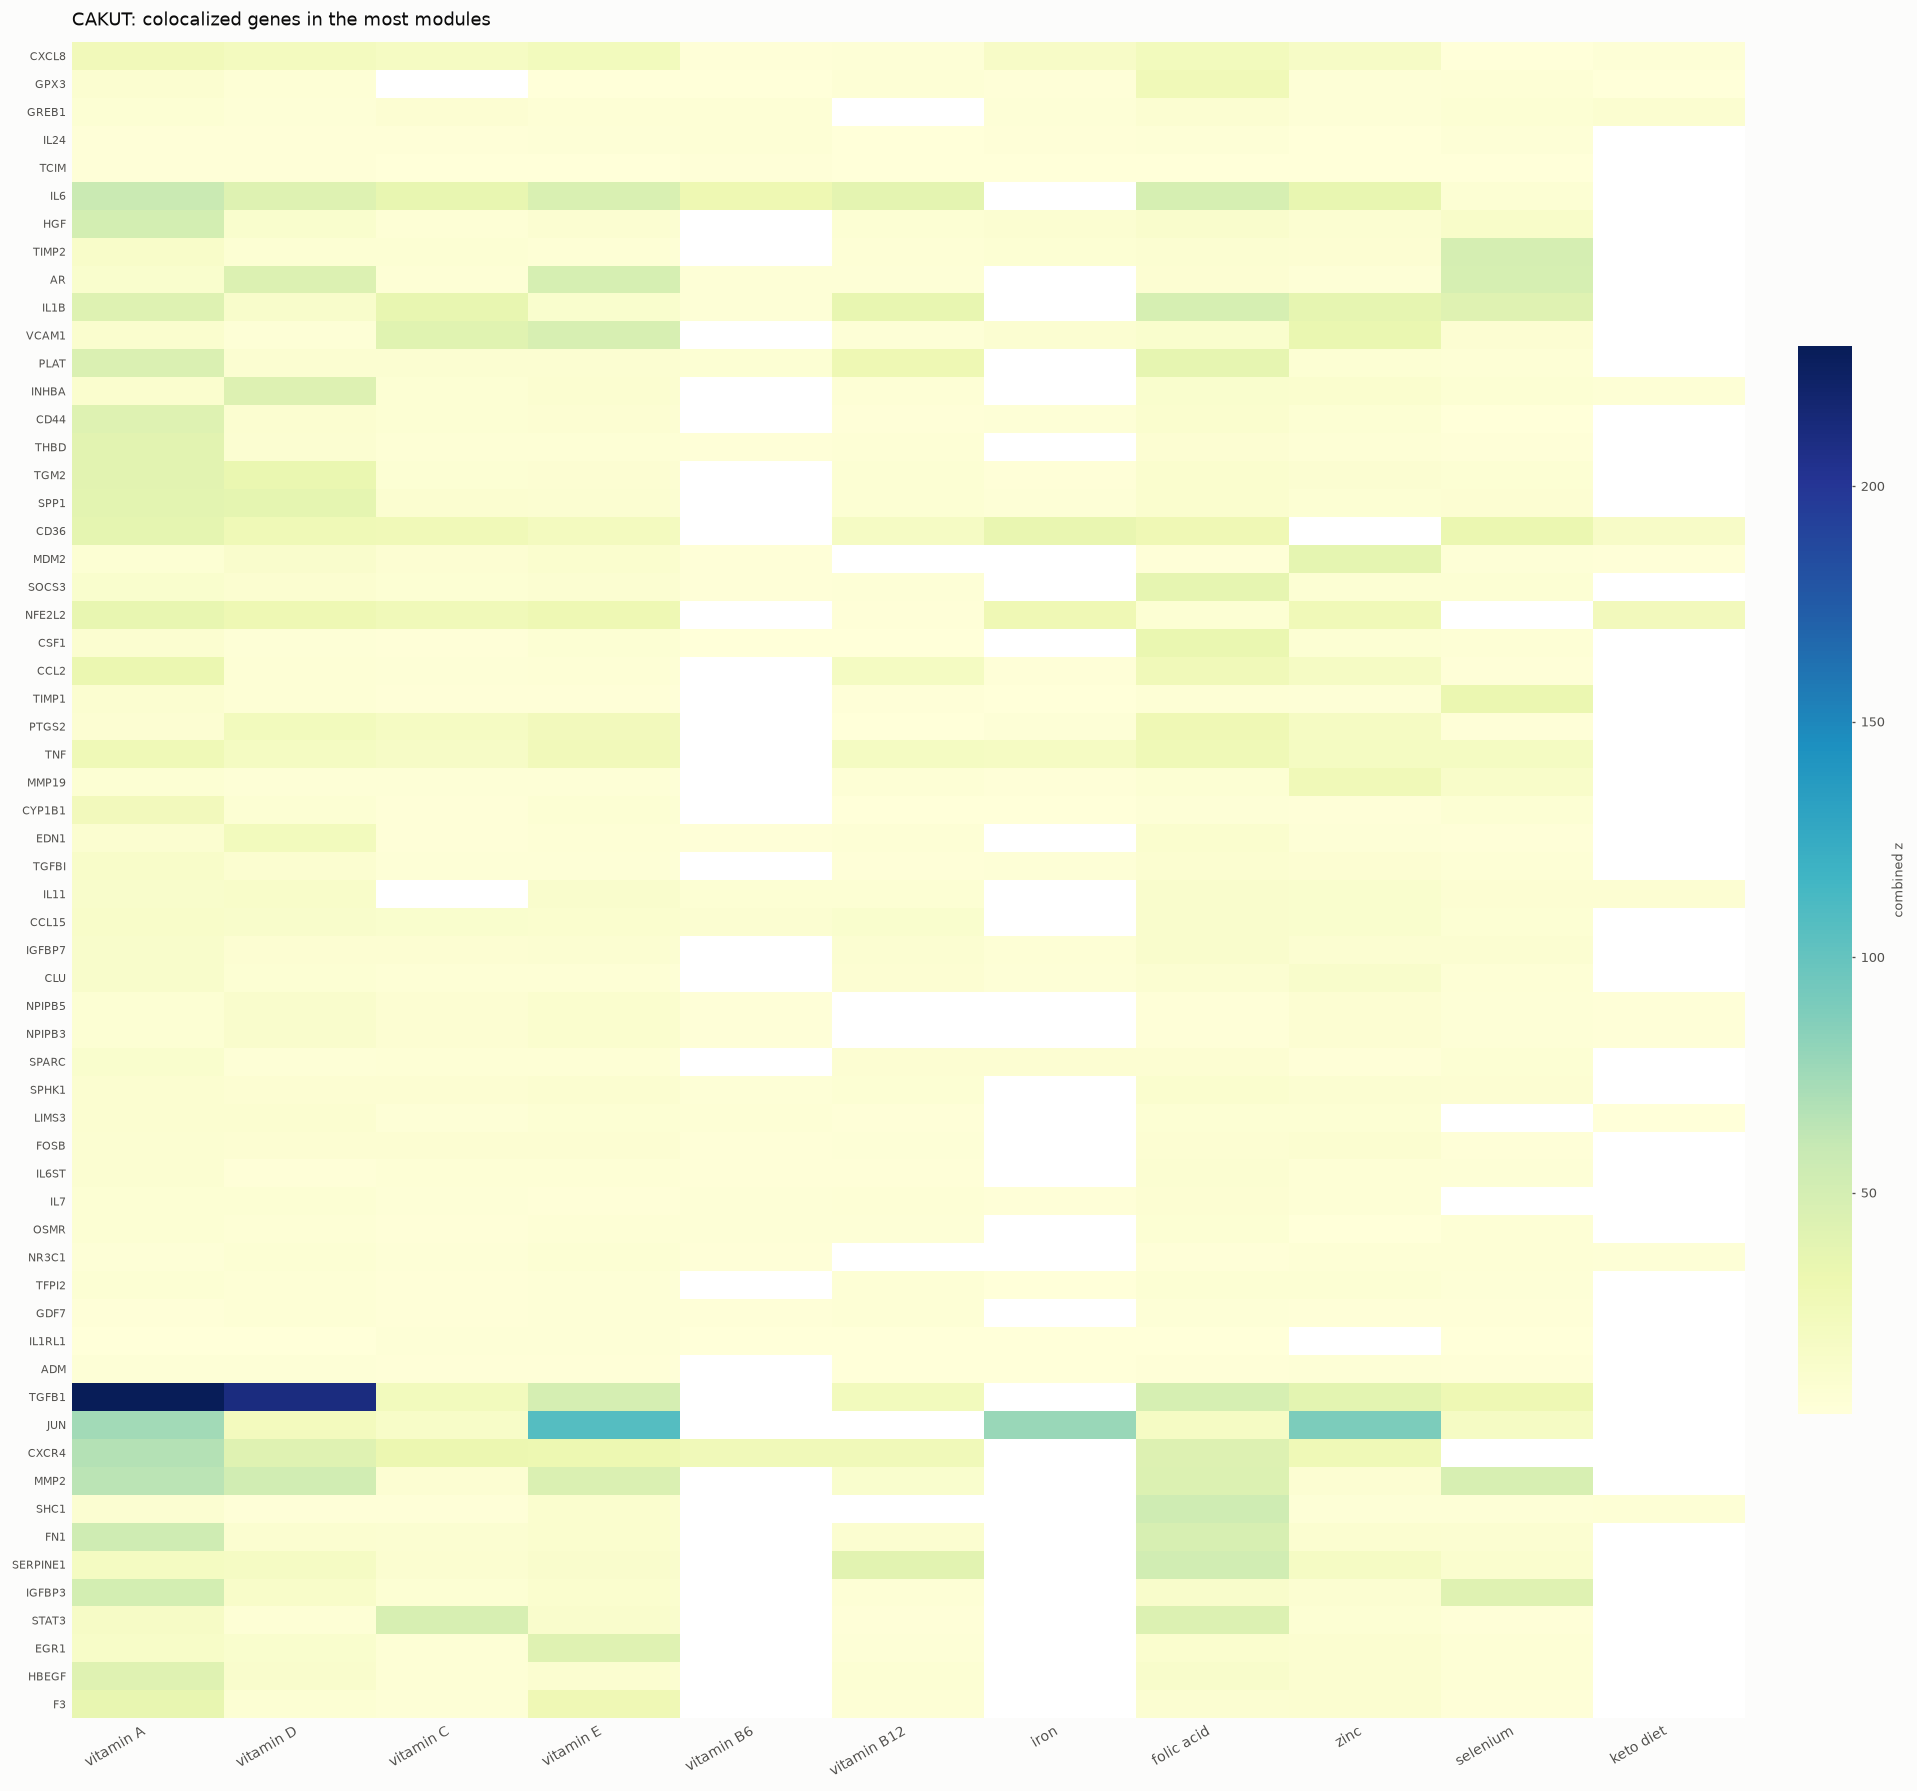

In [14]:
matrices = {}
for disease in mc.DISEASES:
    matrix = mc.coloc_gene_matrix(gene_tables, disease)
    matrices[disease] = matrix
    print(f"{geneset_coloc.LABELS[disease]}: {len(matrix)} genes in at least one module")
    if len(matrix):
        fig = mcf.gene_heatmap(
            matrix,
            out_png=FIGURES / f"fig_gene_heatmap_{disease}.png",
            title=f"{geneset_coloc.LABELS[disease]}: colocalized genes in the most modules",
        )
        plt.show()
        matrix.to_csv(TABLES / f"gene_matrix_{disease}.tsv", sep="\t")

## Part D: g:Profiler on the significant pairs

In [15]:
significant = [
    (row["disease_key"], row["micronutrient_key"])
    for _, row in pair_stats[pair_stats["significant"]].iterrows()
]

annotations = {}
for (disease, nutrient) in sorted(significant):
    # The background is the tissue network of the disease.
    mc.use_disease_network(disease)
    _, nodes, symbol_of, _ = geneset_coloc.network()
    background = geneset_coloc.nps_background(nodes, symbol_of)
    tag = mc.pair_tag(disease, nutrient)
    geneset_coloc.set_pair(f"{mc.OUT.name}/{mc.CACHE.name}/{tag}")
    coloc = results[(disease, nutrient)]["coloc_genes"]
    ann = geneset_coloc.annotate_coloc(coloc, background, out_csv=geneset_coloc.annotation_path(tag))
    annotations[(disease, nutrient)] = ann
    n = 0 if ann is None else len(ann)
    print(f"{geneset_coloc.LABELS[disease]} vs {geneset_coloc.LABELS[nutrient]}: {n} BH-significant terms")


annotating 668 colocalized genes against a background of 13,605


wrote coloc_cakut_folate_annotation_pcnet22_kidney.csv (3969 terms)
CAKUT vs folic acid: 3969 BH-significant terms

annotating 162 colocalized genes against a background of 13,605


wrote coloc_cakut_iron_annotation_pcnet22_kidney.csv (959 terms)
CAKUT vs iron: 959 BH-significant terms

annotating 188 colocalized genes against a background of 13,605


wrote coloc_cakut_keto_annotation_pcnet22_kidney.csv (1472 terms)
CAKUT vs keto diet: 1472 BH-significant terms

annotating 748 colocalized genes against a background of 13,605


wrote coloc_cakut_vita_annotation_pcnet22_kidney.csv (4154 terms)
CAKUT vs vitamin A: 4154 BH-significant terms

annotating 409 colocalized genes against a background of 13,605


...

wrote coloc_dravet_vitb6_annotation_pcnet22_brain.csv (445 terms)
Dravet vs vitamin B6: 445 BH-significant terms

annotating 151 colocalized genes against a background of 16,552


wrote coloc_dravet_vitc_annotation_pcnet22_brain.csv (109 terms)
Dravet vs vitamin C: 109 BH-significant terms

annotating 132 colocalized genes against a background of 16,552


wrote coloc_dravet_vitd_annotation_pcnet22_brain.csv (234 terms)
Dravet vs vitamin D: 234 BH-significant terms

annotating 205 colocalized genes against a background of 16,552


wrote coloc_dravet_vite_annotation_pcnet22_brain.csv (285 terms)
Dravet vs vitamin E: 285 BH-significant terms

annotating 163 colocalized genes against a background of 16,552


wrote coloc_dravet_zinc_annotation_pcnet22_brain.csv (388 terms)
Dravet vs zinc: 388 BH-significant terms


In [16]:
ann_table = mcf.annotation_table(
    annotations, geneset_coloc.LABELS, out_tsv=TABLES / "coloc_annotation_all_pairs.tsv")
print(f"{len(ann_table)} BH-significant terms over "
      f"{ann_table['micronutrient'].nunique() if len(ann_table) else 0} gene sets")
display(ann_table.drop(columns=[c for c in ["intersections"] if c in ann_table]).head(40))

32183 BH-significant terms over 10 gene sets


,disease,micronutrient,source,native,name,p_value,term_size,query_size,intersection_size
0,CAKUT,folic acid,GO:BP,GO:0035295,tube development,1.231180e-120,886,666,242
1,CAKUT,folic acid,GO:BP,GO:0009653,anatomical structure morphogenesis,2.135669e-113,2054,666,345
2,CAKUT,folic acid,GO:BP,GO:0035239,tube morphogenesis,6.726614e-112,722,666,213
3,CAKUT,folic acid,GO:BP,GO:0072359,circulatory system development,8.081705e-111,932,666,237
4,CAKUT,folic acid,GO:BP,GO:0001944,vasculature development,8.081705e-111,632,666,200
5,CAKUT,folic acid,GO:BP,GO:0007167,enzyme-linked receptor protein signaling pathway,6.899161e-110,804,666,221
6,CAKUT,folic acid,GO:BP,GO:0009719,response to endogenous stimulus,1.639207e-108,1180,666,261
7,CAKUT,folic acid,GO:BP,GO:0007166,cell surface receptor signaling pathway,5.283176e-107,2122,666,342
8,CAKUT,folic acid,GO:BP,GO:0048731,system development,4.063395e-106,2979,666,402
9,CAKUT,folic acid,GO:BP,GO:0001568,blood vessel development,5.484953e-106,601,666,191


### D1. The enriched terms per disease

One dot plot per disease, the micronutrients side by side. The colour is
-log10 p and the dot area is the number of query genes in the term.

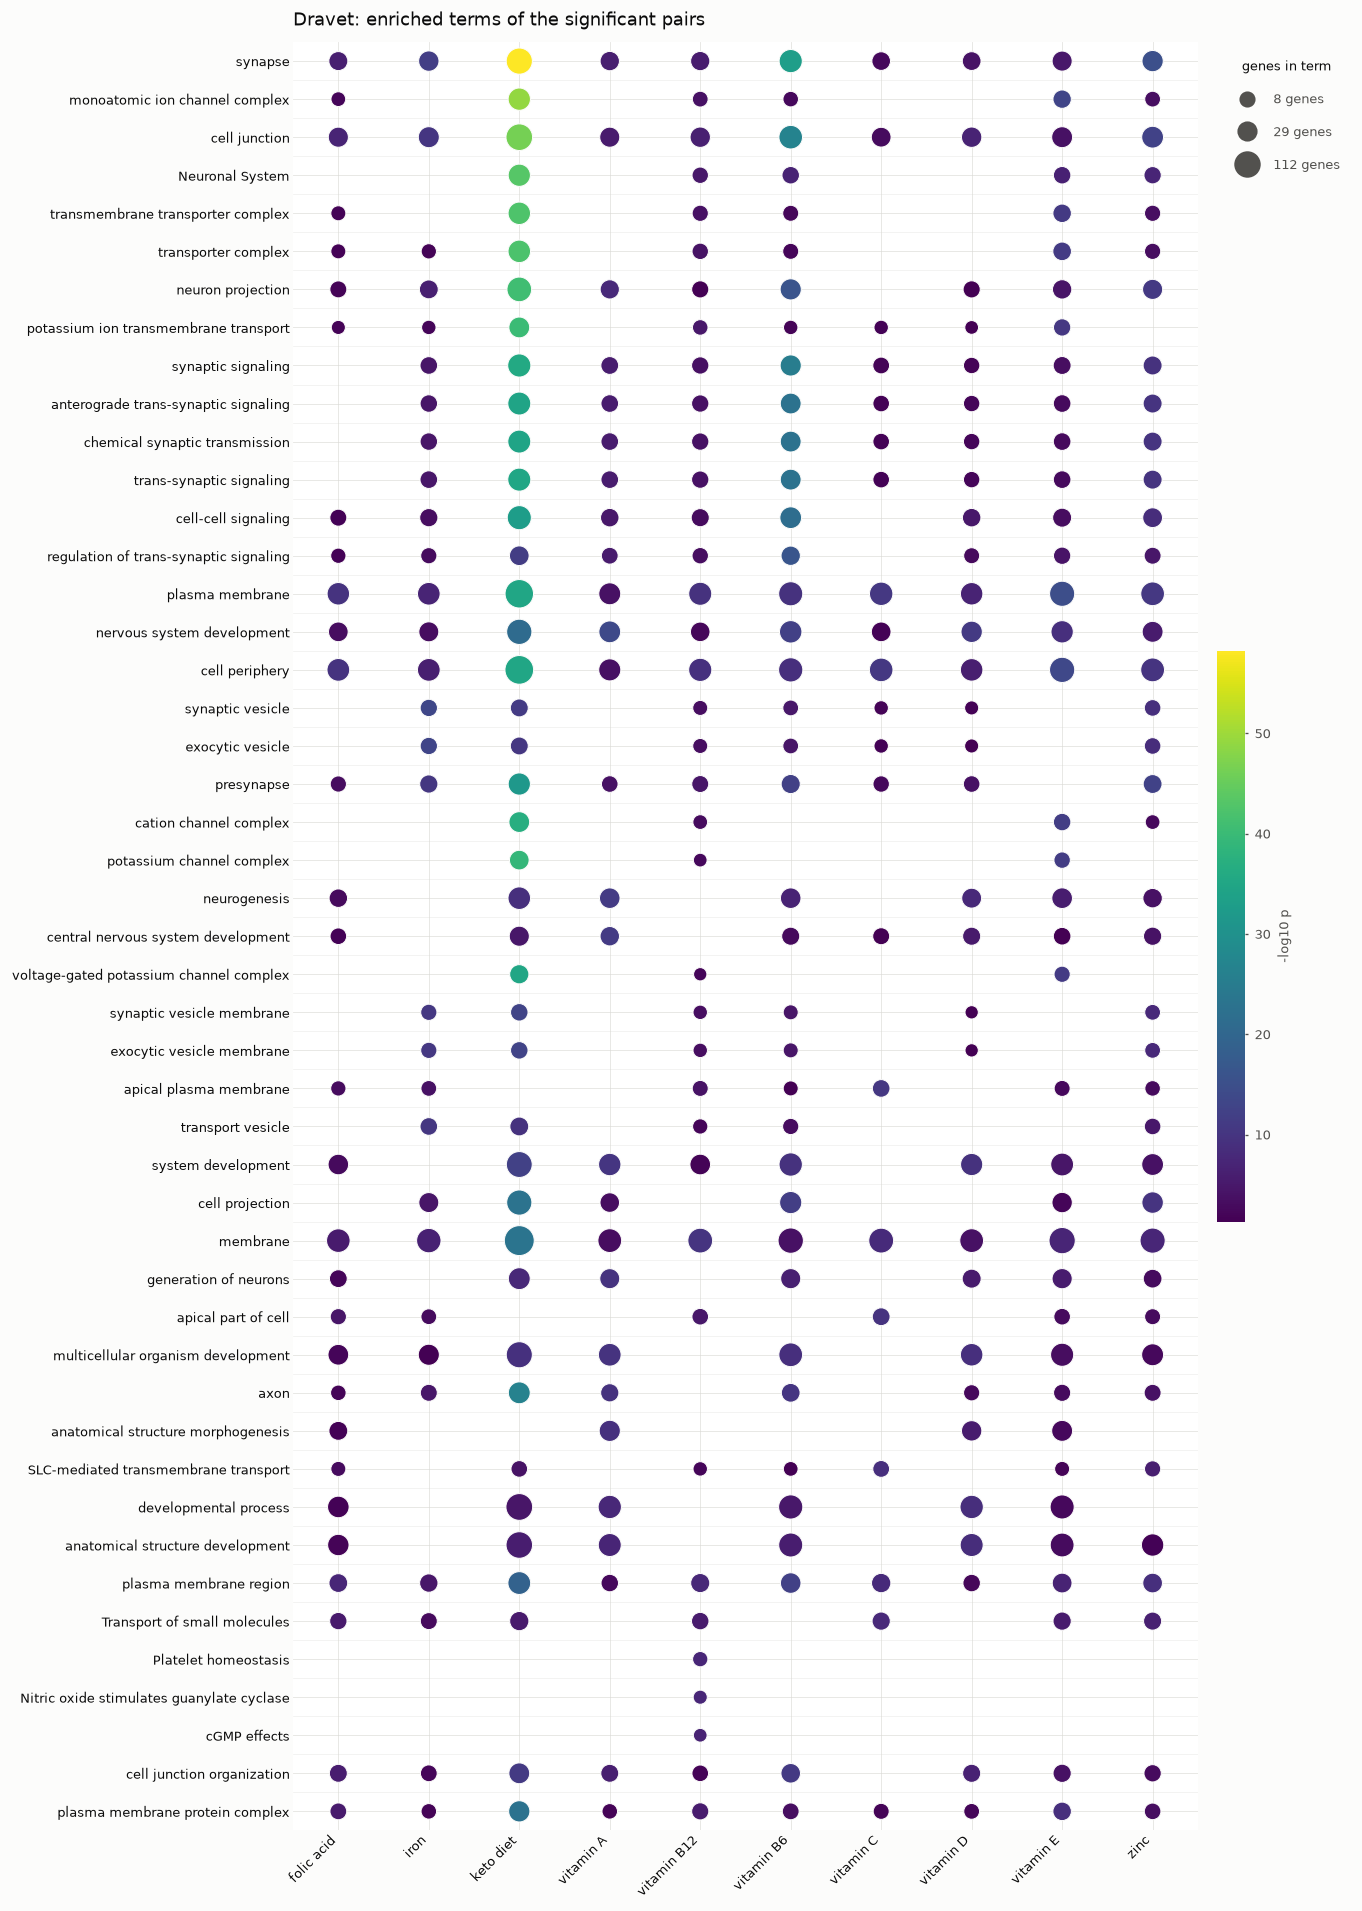

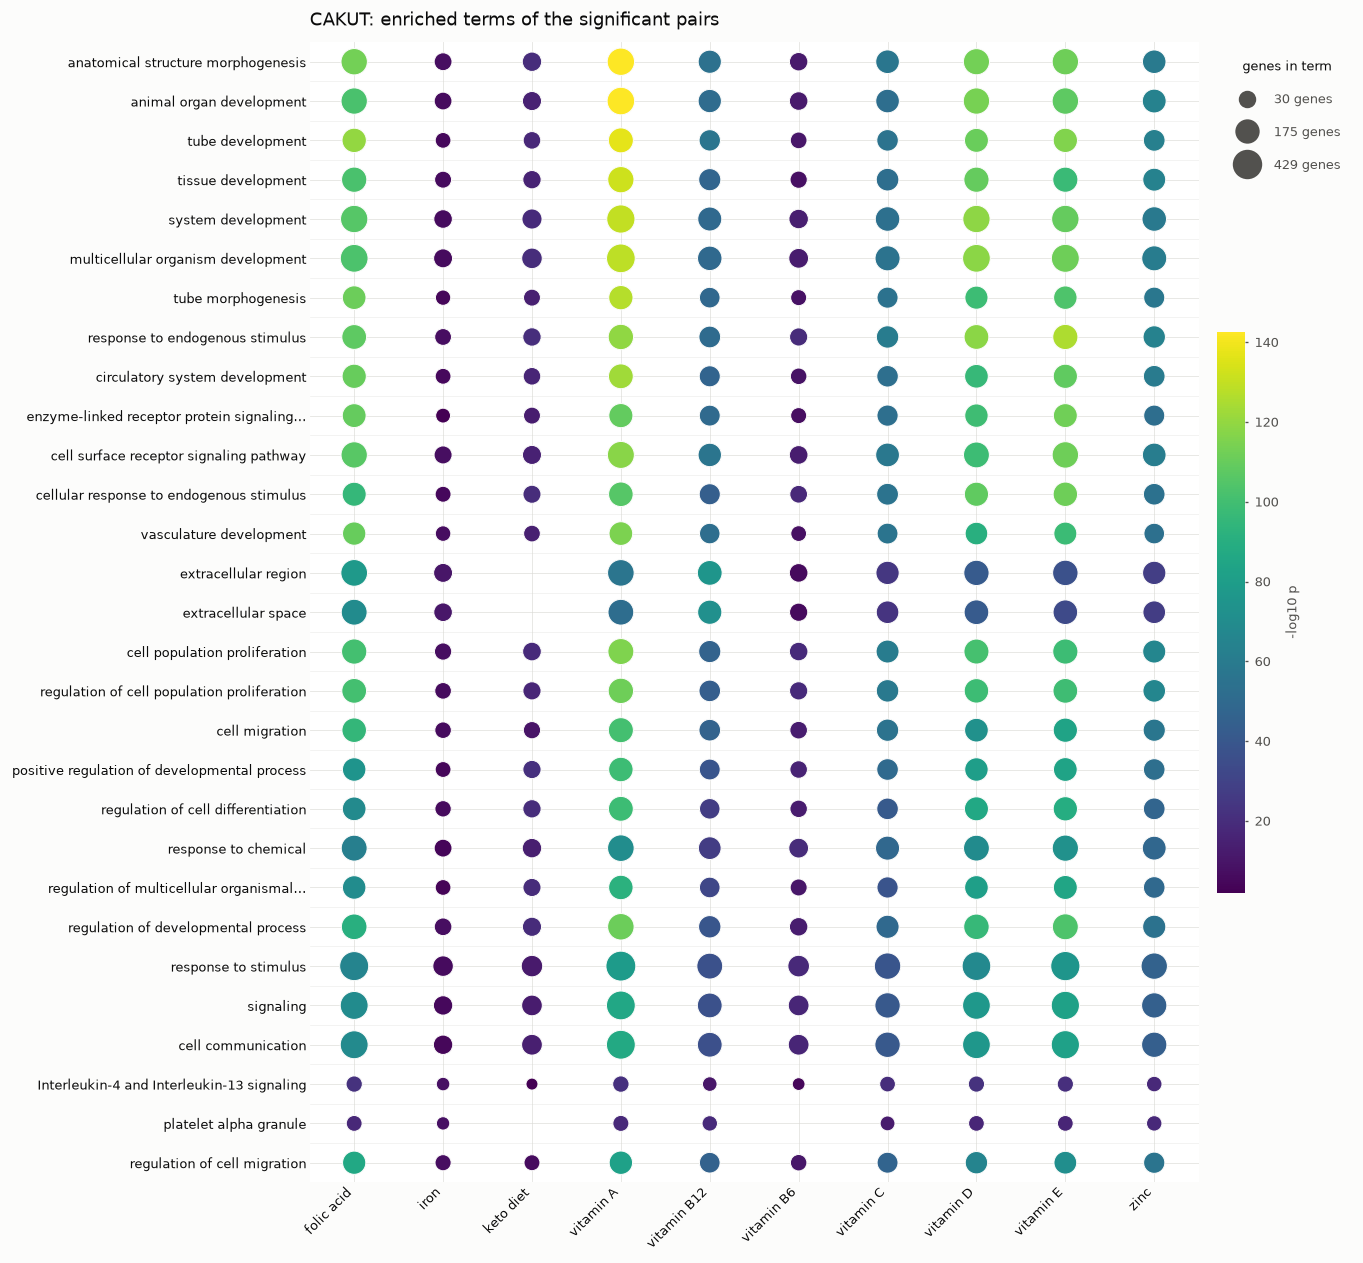

In [17]:
for disease in mc.DISEASES:
    subset = ann_table[ann_table["disease"] == geneset_coloc.LABELS[disease]] if len(ann_table) else ann_table
    if not len(subset):
        print(f"{geneset_coloc.LABELS[disease]}: no enriched term to draw")
        continue
    subset.to_csv(TABLES / f"coloc_annotation_{disease}.tsv", sep="\t", index=False)
    fig = mcf.enrichment_dotplot(
        subset, out_png=FIGURES / f"fig_enrichment_{disease}.png",
        title=f"{geneset_coloc.LABELS[disease]}: enriched terms of the significant pairs",
    )
    plt.show()

### D2. orsum: the collapsed terms

The g:Profiler output holds many redundant terms, because a parent term and its
children are reported separately. orsum reads a ranked term list and keeps a
representative term for every group, where a term represents the less
significant terms it contains.

One orsum run holds the micronutrients of a single disease, each as its own
input file, so the plots carry one column per micronutrient and the two diseases
stay separate. The uncollapsed table of Part D stays as it is; the ranked input
of every micronutrient is written next to the orsum output.

The sources are GO biological process, GO cellular component and Reactome. The
GMT of each one is the g:Profiler file the enrichment was run against.

GO cellular component is empty until Part D is re-run, because the cached
annotation of an earlier run holds no cellular component term.

In [18]:
import coloc_orsum as co

for source, gmt in co.SOURCES.items():
    path = co.GMT_DIR / gmt
    print(f"{source}: {path.name} {'found' if path.exists() else 'MISSING'}")

for disease in mc.DISEASES:
    for source in co.SOURCES:
        for nutrient in co.micronutrients_of(ann_table, disease, source):
            terms = co.ranked_terms(ann_table, disease, source, nutrient)
            print(f"{geneset_coloc.LABELS[disease]} / {source} / {nutrient}: "
                  f"{len(terms)} terms before collapsing")

GO:BP: hsapiens.GO:BP.name.gmt found
GO:CC: hsapiens.GO:CC.name.gmt found
REAC: hsapiens.REAC.name.gmt found
Dravet / GO:BP / folic acid: 168 terms before collapsing
Dravet / GO:BP / iron: 118 terms before collapsing
Dravet / GO:BP / keto diet: 459 terms before collapsing
Dravet / GO:BP / vitamin A: 384 terms before collapsing
Dravet / GO:BP / vitamin B12: 150 terms before collapsing
Dravet / GO:BP / vitamin B6: 347 terms before collapsing
Dravet / GO:BP / vitamin C: 86 terms before collapsing
Dravet / GO:BP / vitamin D: 204 terms before collapsing
Dravet / GO:BP / vitamin E: 213 terms before collapsing
Dravet / GO:BP / zinc: 260 terms before collapsing
Dravet / GO:CC / folic acid: 43 terms before collapsing
Dravet / GO:CC / iron: 79 terms before collapsing
Dravet / GO:CC / keto diet: 138 terms before collapsing
Dravet / GO:CC / vitamin A: 53 terms before collapsing
Dravet / GO:CC / vitamin B12: 62 terms before collapsing
Dravet / GO:CC / vitamin B6: 75 terms before collapsing
Dravet /

Dravet / GO:CC / vitamin D: 30 terms before collapsing
Dravet / GO:CC / vitamin E: 47 terms before collapsing
Dravet / GO:CC / zinc: 99 terms before collapsing
Dravet / REAC / folic acid: 13 terms before collapsing
Dravet / REAC / iron: 8 terms before collapsing
Dravet / REAC / keto diet: 49 terms before collapsing
Dravet / REAC / vitamin A: 25 terms before collapsing
Dravet / REAC / vitamin B12: 59 terms before collapsing
Dravet / REAC / vitamin B6: 23 terms before collapsing
Dravet / REAC / vitamin C: 3 terms before collapsing
Dravet / REAC / vitamin E: 25 terms before collapsing
Dravet / REAC / zinc: 29 terms before collapsing
CAKUT / GO:BP / folic acid: 3350 terms before collapsing
CAKUT / GO:BP / iron: 635 terms before collapsing
CAKUT / GO:BP / keto diet: 1277 terms before collapsing
CAKUT / GO:BP / vitamin A: 3480 terms before collapsing
CAKUT / GO:BP / vitamin B12: 2196 terms before collapsing


CAKUT / GO:BP / vitamin B6: 1348 terms before collapsing
CAKUT / GO:BP / vitamin C: 2540 terms before collapsing
CAKUT / GO:BP / vitamin D: 3227 terms before collapsing
CAKUT / GO:BP / vitamin E: 3444 terms before collapsing
CAKUT / GO:BP / zinc: 2799 terms before collapsing
CAKUT / GO:CC / folic acid: 169 terms before collapsing
CAKUT / GO:CC / iron: 52 terms before collapsing
CAKUT / GO:CC / keto diet: 16 terms before collapsing
CAKUT / GO:CC / vitamin A: 178 terms before collapsing
CAKUT / GO:CC / vitamin B12: 112 terms before collapsing
CAKUT / GO:CC / vitamin B6: 28 terms before collapsing
CAKUT / GO:CC / vitamin C: 99 terms before collapsing
CAKUT / GO:CC / vitamin D: 159 terms before collapsing
CAKUT / GO:CC / vitamin E: 148 terms before collapsing
CAKUT / GO:CC / zinc: 114 terms before collapsing
CAKUT / REAC / folic acid: 450 terms before collapsing
CAKUT / REAC / iron: 272 terms before collapsing


CAKUT / REAC / keto diet: 179 terms before collapsing
CAKUT / REAC / vitamin A: 496 terms before collapsing
CAKUT / REAC / vitamin B12: 236 terms before collapsing
CAKUT / REAC / vitamin B6: 108 terms before collapsing
CAKUT / REAC / vitamin C: 346 terms before collapsing
CAKUT / REAC / vitamin D: 495 terms before collapsing
CAKUT / REAC / vitamin E: 568 terms before collapsing
CAKUT / REAC / zinc: 393 terms before collapsing


In [19]:
orsum_summary = co.run(ann_table, min_term_size=10, max_rep_size=2000,
                       n_plot=50)
print(f"\nwrote {co.out_dir()}")


Dravet / GO:BP: collapsing 10 micronutrients, 2389 terms



Dravet / GO:CC: collapsing 10 micronutrients, 646 terms



Dravet / REAC: collapsing 9 micronutrients, 234 terms



CAKUT / GO:BP: collapsing 10 micronutrients, 24296 terms



CAKUT / GO:CC: collapsing 10 micronutrients, 1075 terms



CAKUT / REAC: collapsing 10 micronutrients, 3543 terms



wrote /home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/orsum


#### The representative terms

One table per disease and source. `Represented term number` is the number of
terms the representative stands for, and the per-micronutrient rank columns give
the rank of the representative under that micronutrient, or an empty cell when
the term is not enriched there.

In [20]:
collapsed = {}
for (disease, source) in orsum_summary:
    table = co.collapsed_table(orsum_summary, disease, source)
    collapsed[(disease, source)] = table
    table.to_csv(TABLES / f"orsum_collapsed_{disease}_{source.replace(':', '')}.tsv",
                 sep="\t", index=False)
    print(f"\n{geneset_coloc.LABELS[disease]} / {source}: {len(table)} representative terms")
    display(table.head(20))


Dravet / GO:BP: 266 representative terms


,Representing term id,Representing term name,Representing term size,Representing term rank,Represented term number,folic acid term rank,iron term rank,keto diet term rank,vitamin A term rank,vitamin B12 term rank,vitamin B6 term rank,vitamin C term rank,vitamin D term rank,vitamin E term rank,zinc term rank
0,GO:0034330,cell junction organization,829,1,42,1.0,65.0,22.0,33.0,89.0,8.0,NaN,7.0,43.0,92.0
1,GO:0006810,transport,4368,1,1,57.0,1.0,18.0,369.0,4.0,78.0,45.0,NaN,27.0,16.0
2,GO:0071805,potassium ion transmembrane transport,199,1,8,59.0,67.0,1.0,NaN,11.0,200.0,36.0,183.0,1.0,NaN
3,GO:0007399,nervous system development,2597,1,1,6.0,28.0,17.0,1.0,57.0,9.0,35.0,1.0,9.0,26.0
4,GO:0006811,monoatomic ion transport,1260,1,49,3.0,3.0,2.0,NaN,1.0,37.0,2.0,145.0,2.0,6.0
5,GO:0099536,synaptic signaling,803,1,44,81.0,11.0,6.0,45.0,15.0,1.0,32.0,44.0,34.0,1.0
6,GO:0055085,transmembrane transport,1554,1,26,5.0,6.0,11.0,NaN,8.0,72.0,1.0,NaN,3.0,8.0
7,GO:0051234,establishment of localization,4739,2,1,93.0,2.0,19.0,359.0,7.0,93.0,71.0,NaN,32.0,25.0
8,GO:0007417,central nervous system development,1035,2,47,47.0,NaN,124.0,2.0,96.0,109.0,38.0,20.0,68.0,45.0
9,GO:0048731,system development,4022,2,1,25.0,NaN,27.0,4.0,93.0,12.0,NaN,2.0,31.0,52.0



Dravet / GO:CC: 60 representative terms


,Representing term id,Representing term name,Representing term size,Representing term rank,Represented term number,folic acid term rank,iron term rank,keto diet term rank,vitamin A term rank,vitamin B12 term rank,vitamin B6 term rank,vitamin C term rank,vitamin D term rank,vitamin E term rank,zinc term rank
0,GO:0005886,plasma membrane,5899,1,1,1.0,12.0,10.0,17.0,2.0,13.0,1.0,1.0,1.0,5.0
1,GO:0008021,synaptic vesicle,217,1,3,NaN,1.0,33.0,NaN,14.0,27.0,13.0,21.0,NaN,10.0
2,GO:0045202,synapse,1607,1,36,5.0,3.0,1.0,5.0,7.0,1.0,8.0,4.0,13.0,1.0
3,GO:0030424,axon,633,1,10,29.0,20.0,17.0,1.0,NaN,12.0,NaN,10.0,23.0,28.0
4,GO:0016020,membrane,9965,1,1,6.0,13.0,20.0,26.0,1.0,37.0,5.0,6.0,10.0,15.0
5,GO:0071944,cell periphery,6256,2,1,2.0,15.0,11.0,20.0,3.0,14.0,3.0,3.0,2.0,7.0
6,GO:0070382,exocytic vesicle,235,2,1,NaN,2.0,38.0,NaN,19.0,28.0,15.0,24.0,NaN,11.0
7,GO:0034702,monoatomic ion channel complex,369,2,13,21.0,NaN,2.0,NaN,12.0,50.0,NaN,NaN,3.0,31.0
8,GO:0036477,somatodendritic compartment,826,2,10,33.0,21.0,13.0,2.0,60.0,7.0,NaN,16.0,30.0,24.0
9,GO:0030054,cell junction,2368,2,1,4.0,8.0,3.0,8.0,5.0,2.0,7.0,2.0,16.0,2.0



Dravet / REAC: 41 representative terms


...

,Representing term id,Representing term name,Representing term size,Representing term rank,Represented term number,folic acid term rank,iron term rank,keto diet term rank,vitamin A term rank,vitamin B12 term rank,vitamin B6 term rank,vitamin C term rank,vitamin D term rank,vitamin E term rank,zinc term rank
0,GO:0035295,tube development,1094,1,116,1.0,17.0,13.0,3.0,2.0,53.0,9.0,6.0,2.0,6.0
1,GO:0007166,cell surface receptor signaling pathway,2829,1,1,8.0,1.0,20.0,11.0,1.0,30.0,4.0,15.0,4.0,7.0
2,GO:0051094,positive regulation of developmental process,1305,1,73,42.0,72.0,1.0,28.0,36.0,14.0,23.0,30.0,30.0,29.0
3,GO:0009653,anatomical structure morphogenesis,2699,1,1,2.0,5.0,5.0,1.0,3.0,39.0,5.0,5.0,7.0,10.0
4,GO:0009719,response to endogenous stimulus,1466,1,105,7.0,2.0,2.0,10.0,6.0,1.0,1.0,3.0,1.0,3.0
5,GO:0048731,system development,4022,1,1,9.0,15.0,9.0,5.0,9.0,21.0,12.0,1.0,8.0,11.0
6,GO:0008283,cell population proliferation,1957,1,117,14.0,4.0,10.0,15.0,15.0,3.0,2.0,10.0,14.0,1.0
7,GO:0048513,animal organ development,3018,2,1,13.0,22.0,22.0,2.0,5.0,44.0,17.0,4.0,10.0,5.0
8,GO:0042221,response to chemical,3859,2,1,53.0,85.0,33.0,59.0,66.0,2.0,27.0,40.0,40.0,40.0
9,GO:0007275,multicellular organism development,4689,2,1,11.0,19.0,4.0,6.0,8.0,35.0,7.0,2.0,5.0,8.0



CAKUT / GO:CC: 84 representative terms


,Representing term id,Representing term name,Representing term size,Representing term rank,Represented term number,folic acid term rank,iron term rank,keto diet term rank,vitamin A term rank,vitamin B12 term rank,vitamin B6 term rank,vitamin C term rank,vitamin D term rank,vitamin E term rank,zinc term rank
0,GO:0005576,extracellular region,4244,1,1,1.0,2.0,NaN,1.0,1.0,2.0,2.0,2.0,1.0,1.0
1,GO:0005615,extracellular space,3250,1,1,2.0,1.0,NaN,4.0,2.0,1.0,3.0,1.0,2.0,2.0
2,GO:0000785,chromatin,1407,1,2,31.0,NaN,1.0,8.0,NaN,4.0,8.0,6.0,6.0,11.0
3,GO:0009986,cell surface,900,1,2,6.0,7.0,NaN,5.0,5.0,3.0,1.0,7.0,3.0,5.0
4,GO:0005694,chromosome,2008,2,1,72.0,NaN,2.0,15.0,NaN,19.0,22.0,13.0,13.0,27.0
5,GO:0031012,extracellular matrix,339,2,15,3.0,5.0,NaN,2.0,3.0,NaN,6.0,3.0,7.0,3.0
6,GO:0031091,platelet alpha granule,91,3,3,12.0,3.0,NaN,14.0,9.0,NaN,12.0,12.0,11.0,7.0
7,GO:0005667,transcription regulator complex,518,3,5,23.0,NaN,3.0,11.0,NaN,13.0,13.0,11.0,9.0,15.0
8,GO:0030312,external encapsulating structure,340,3,1,4.0,6.0,NaN,3.0,4.0,NaN,5.0,4.0,8.0,4.0
9,GO:0071944,cell periphery,6256,4,1,5.0,4.0,NaN,7.0,6.0,5.0,4.0,8.0,5.0,6.0



CAKUT / REAC: 163 representative terms


,Representing term id,Representing term name,Representing term size,Representing term rank,Represented term number,folic acid term rank,iron term rank,keto diet term rank,vitamin A term rank,vitamin B12 term rank,vitamin B6 term rank,vitamin C term rank,vitamin D term rank,vitamin E term rank,zinc term rank
0,REAC:R-HSA-1474244,Extracellular matrix organization,298,1,17,1.0,3.0,NaN,1.0,1.0,85.0,1.0,2.0,4.0,2.0
1,REAC:R-HSA-6785807,Interleukin-4 and Interleukin-13 signaling,111,1,1,9.0,1.0,83.0,12.0,14.0,20.0,5.0,11.0,11.0,4.0
2,REAC:R-HSA-162582,Signal Transduction,2568,1,1,3.0,8.0,1.0,2.0,4.0,2.0,2.0,1.0,1.0,1.0
3,REAC:R-HSA-383280,Nuclear Receptor transcription pathway,41,1,1,108.0,NaN,10.0,25.0,NaN,1.0,68.0,23.0,59.0,123.0
4,REAC:R-HSA-9006934,Signaling by Receptor Tyrosine Kinases,516,2,97,2.0,13.0,4.0,3.0,6.0,6.0,3.0,3.0,2.0,3.0
5,REAC:R-HSA-4641263,Regulation of FZD by ubiquitination,21,2,1,301.0,2.0,NaN,271.0,NaN,NaN,NaN,183.0,NaN,NaN
6,REAC:R-HSA-5663202,Diseases of signal transduction by growth fact...,449,2,42,23.0,54.0,2.0,16.0,35.0,12.0,18.0,9.0,6.0,19.0
7,REAC:R-HSA-1266738,Developmental Biology,1394,3,59,8.0,93.0,3.0,5.0,54.0,8.0,7.0,4.0,3.0,16.0
8,REAC:R-HSA-2151201,Transcriptional activation of mitochondrial bi...,52,3,1,NaN,NaN,119.0,322.0,NaN,3.0,NaN,186.0,385.0,228.0
9,REAC:R-HSA-449147,Signaling by Interleukins,471,4,32,12.0,4.0,59.0,29.0,19.0,14.0,4.0,22.0,9.0,6.0


#### The orsum plots

One heatmap per disease and source, with the micronutrients as the columns.


Dravet / GO:BP


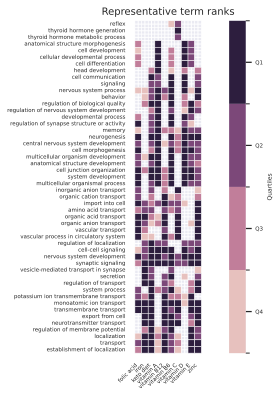

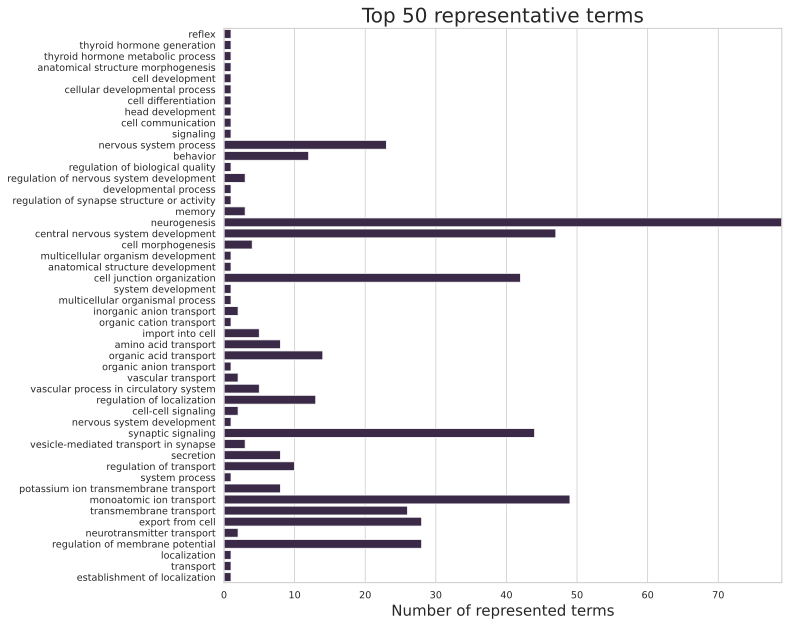


Dravet / GO:CC


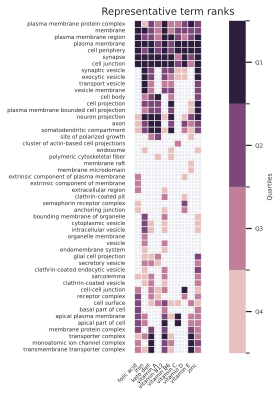

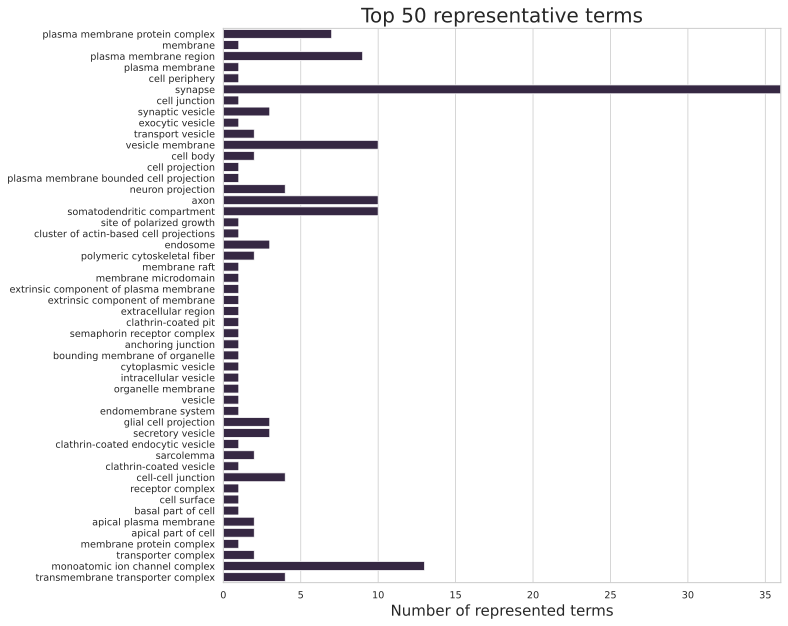


Dravet / REAC


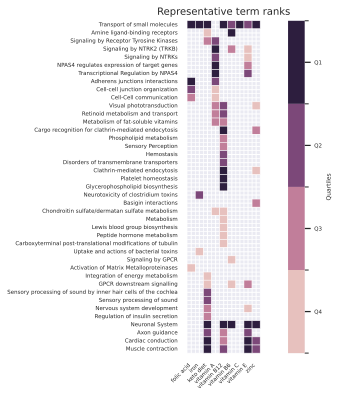

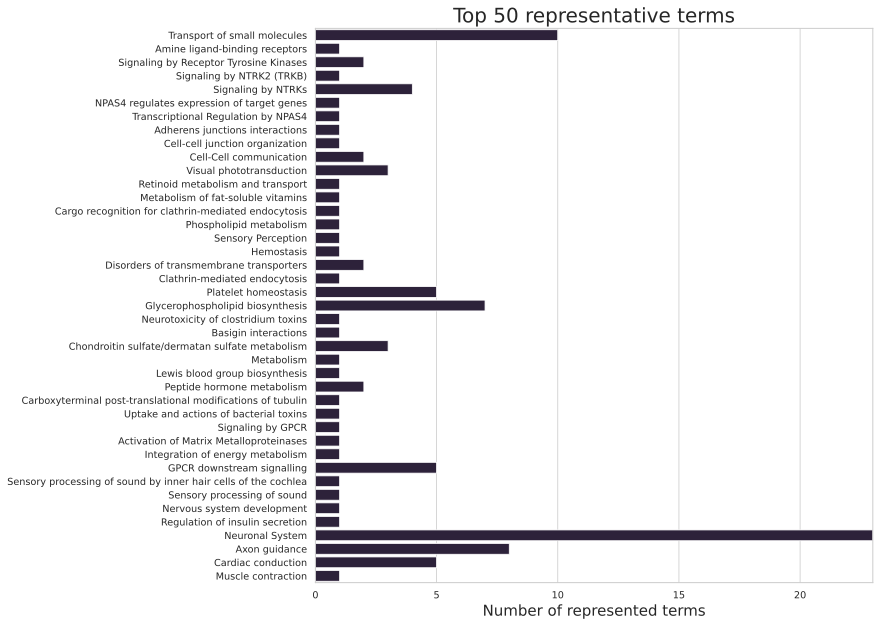


CAKUT / GO:BP


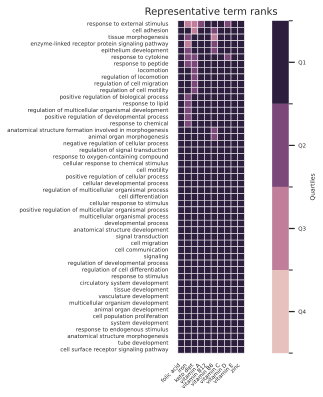

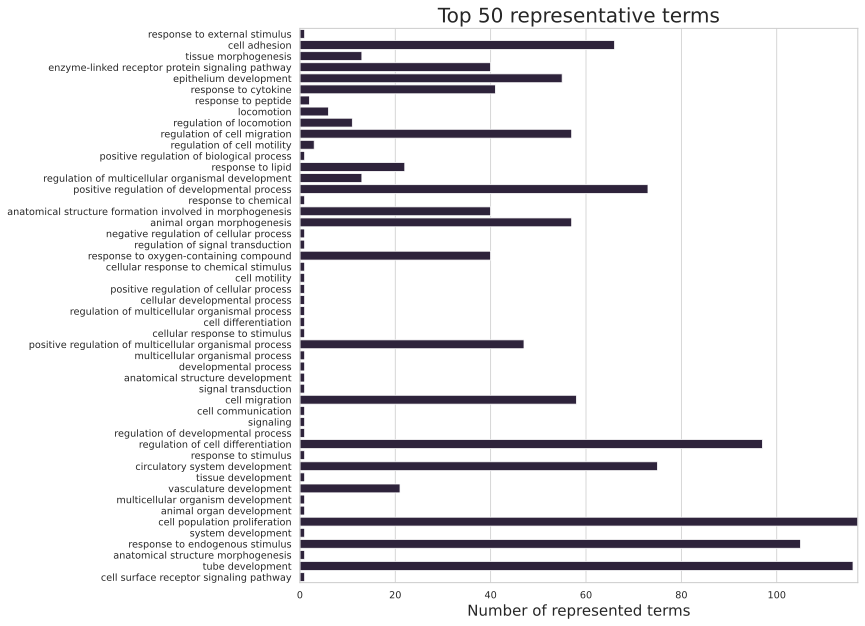


CAKUT / GO:CC


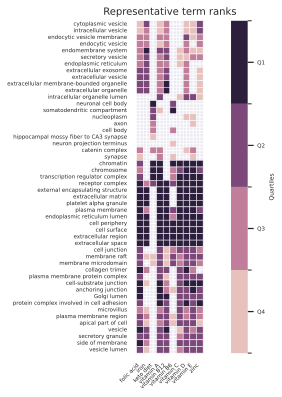

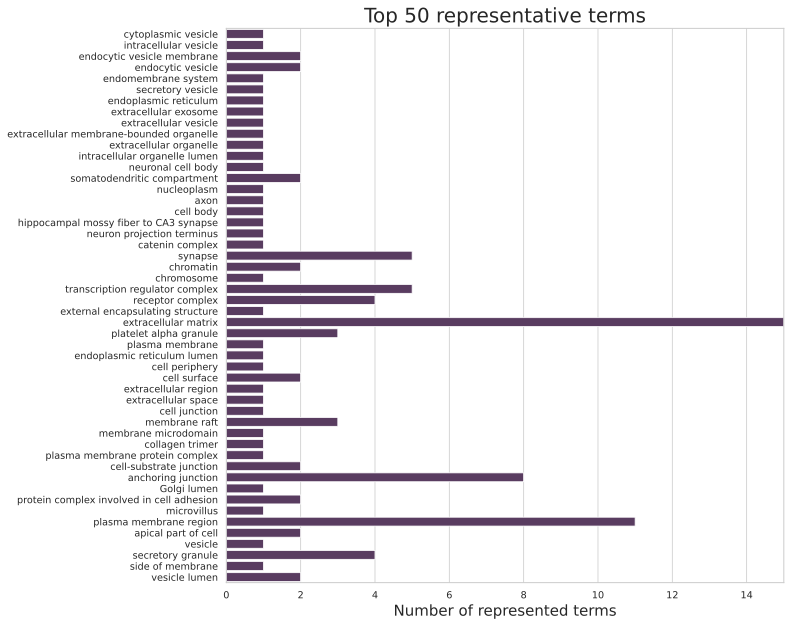


CAKUT / REAC


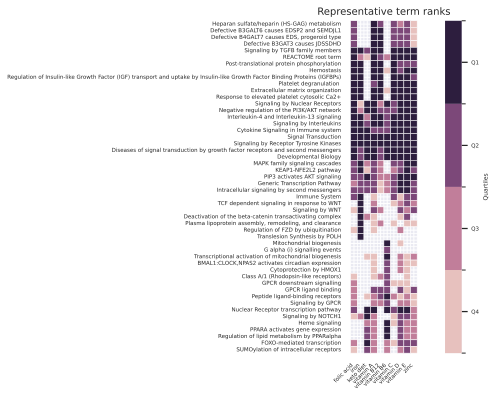

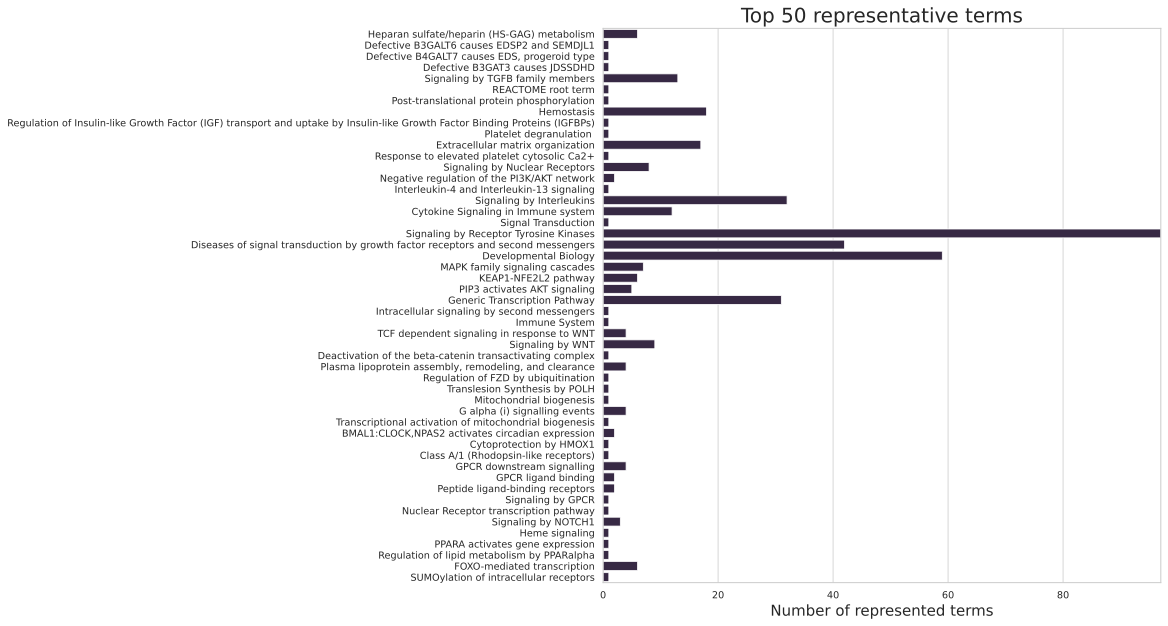

In [21]:
from IPython.display import SVG, display as _display

for (disease, source) in orsum_summary:
    folder = orsum_summary[(disease, source)]["output"]
    print(f"\n{geneset_coloc.LABELS[disease]} / {source}")
    for name in ("HeatmapClustered.svg", "Barplot.svg"):
        path = folder / name
        if path.exists():
            _display(SVG(filename=str(path)))

## Part E: the knowledge graph of each disease

Three node types: a `micronutrient` gene set, a `gene` of a colocalized module,
and a `pathway` term of Part D. Only the significant pairs of the disease enter
its graph. A gene takes its micronutrient's colour, or a pie when several reach
it; a disease seed is red, being an input.

In [22]:
import dravet_coloc_kg as dkg

edges = mc.coloc_edges(gene_tables, results)
edges.to_csv(TABLES / "coloc_edges.tsv", sep="\t", index=False)

kg_inputs, graphs = {}, {}
for disease in mc.DISEASES:
    label = geneset_coloc.LABELS[disease]
    significant_nutrients = pair_stats.loc[
        pair_stats["significant"] & (pair_stats["disease_key"] == disease), "micronutrient"]
    kg_edges = edges[(edges["disease"] == label)
                     & edges["micronutrient"].isin(significant_nutrients)]
    if not len(kg_edges):
        print(f"{label}: no significant pair")
        continue
    kg_annotation = (ann_table[ann_table["disease"] == label]
                     if len(ann_table) else None)
    kg_inputs[disease] = (kg_edges, kg_annotation)
    graphs[disease] = dkg.build(kg_edges, kg_annotation)
    node_counts, edge_counts = dkg.summary(graphs[disease])
    print(f"{label}\n{node_counts.to_string()}\n{edge_counts.to_string()}\n")

Dravet
gene             914
pathway           32
micronutrient     10
coloc       1710
enriched      50



CAKUT
gene             1285
pathway            22
micronutrient      10
coloc       4520
enriched      50



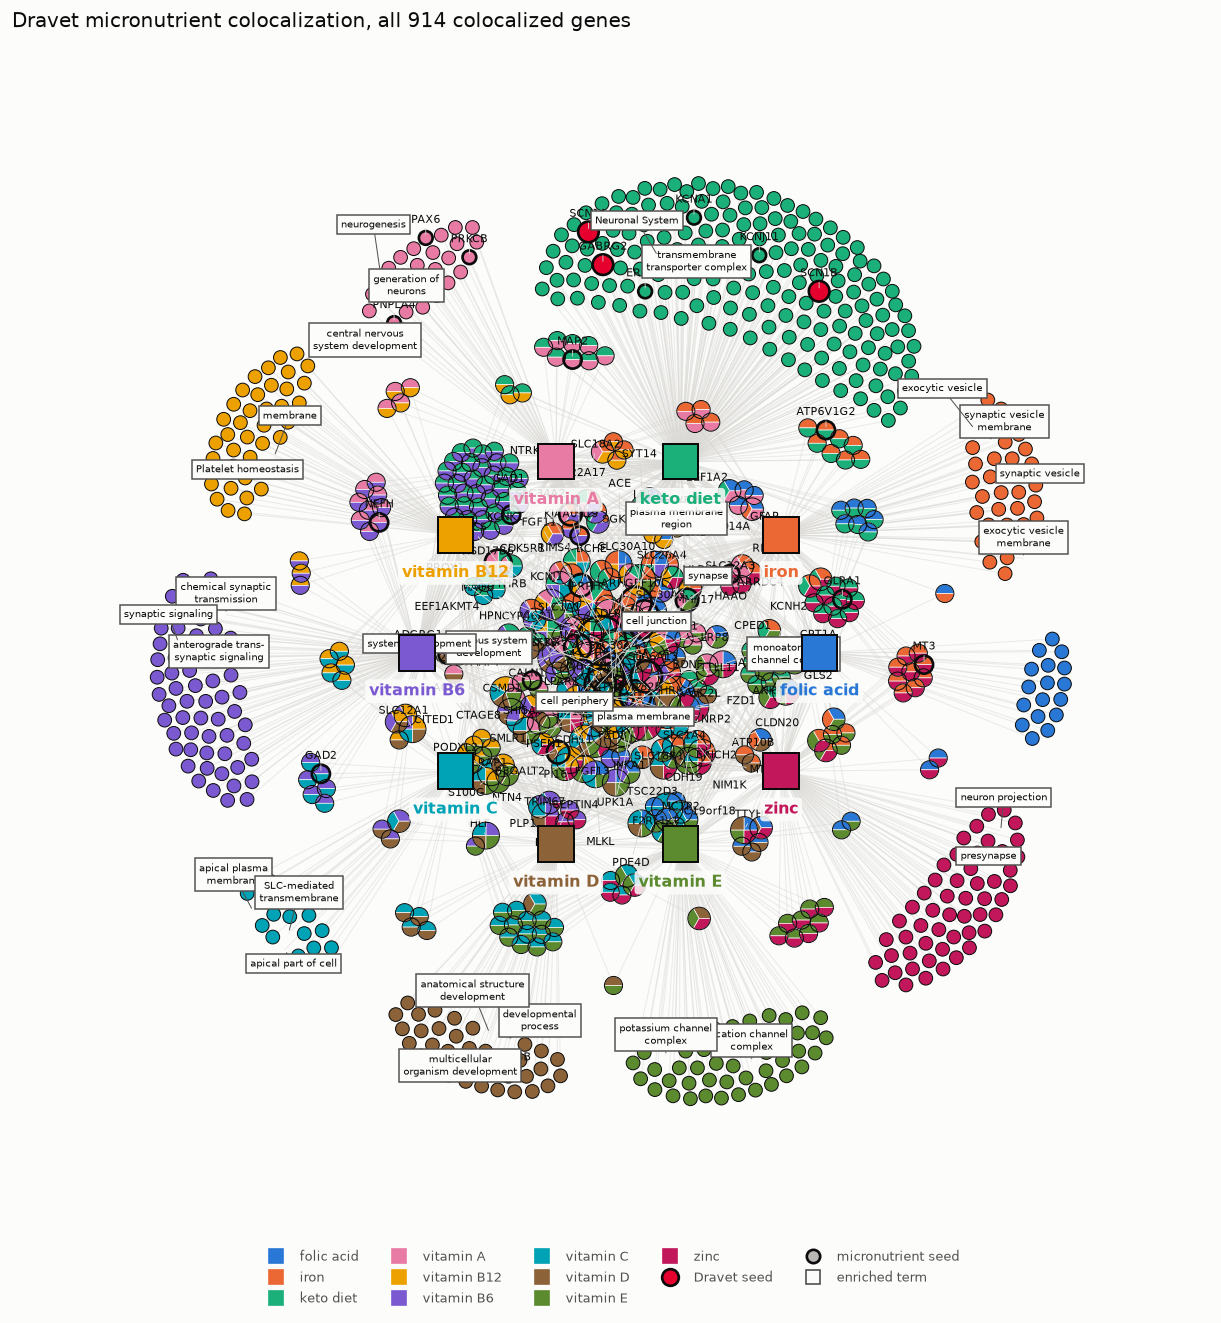

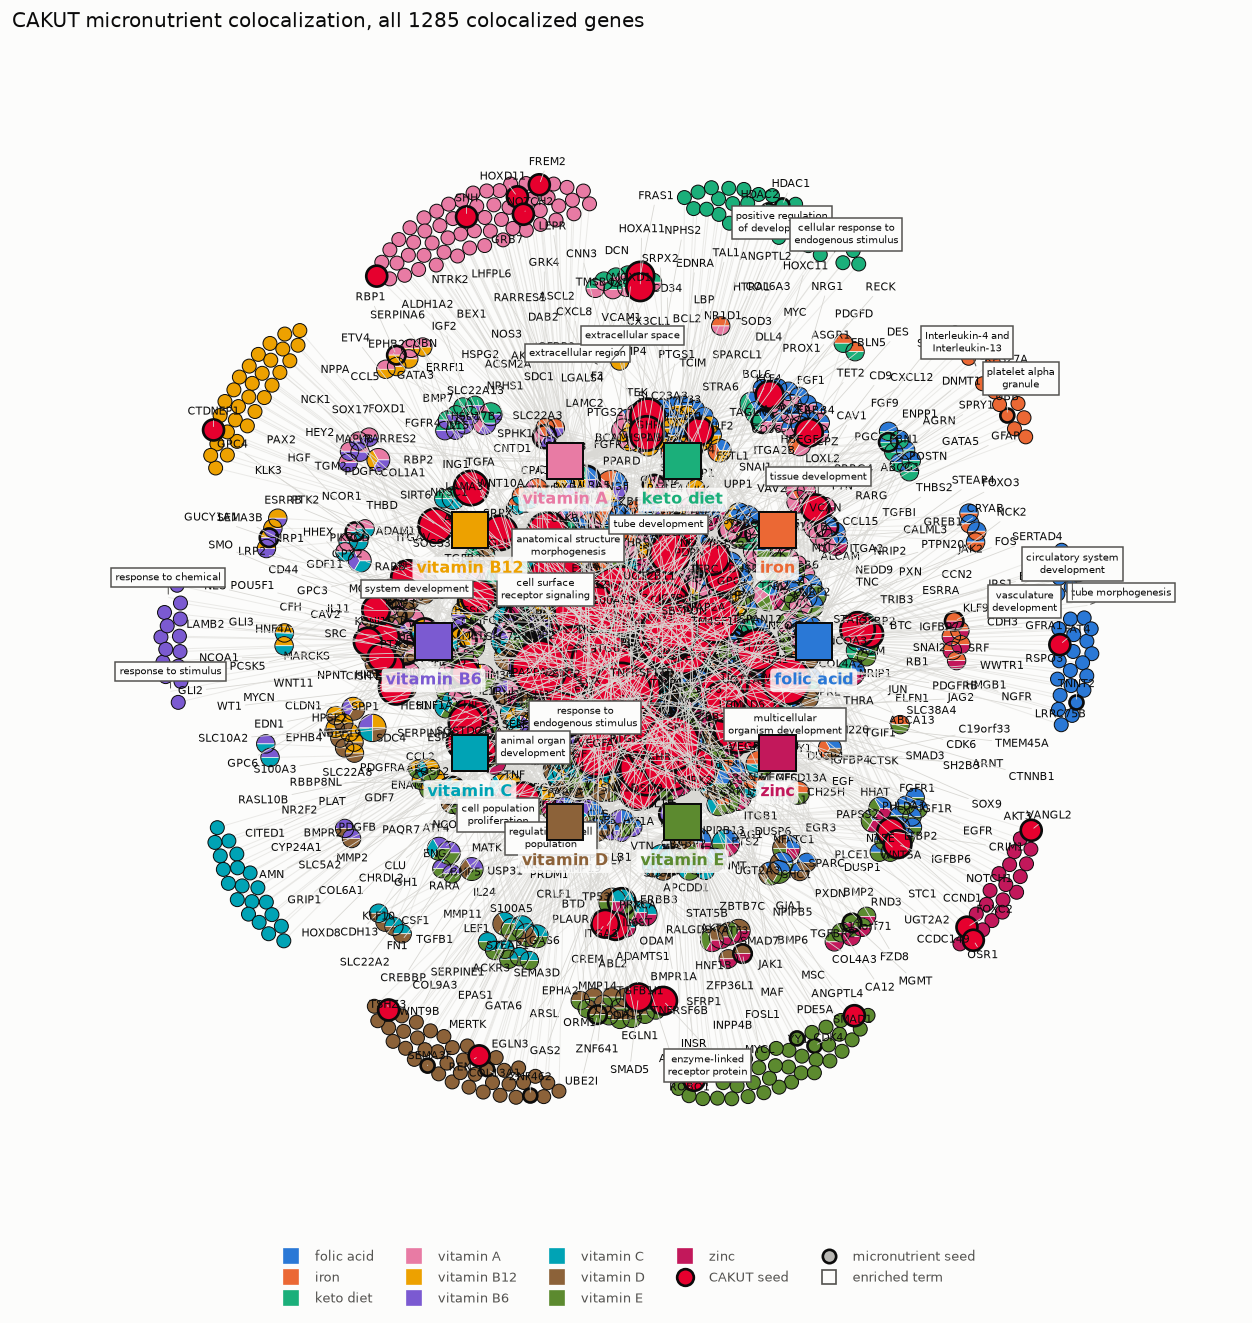

In [23]:
for disease, graph in graphs.items():
    n_genes = dkg.summary(graph)[0]["gene"]
    fig = dkg.draw(
        graph, out_png=FIGURES / f"fig_{disease}_kg_full.png", label_min=4,
        title=f"{geneset_coloc.LABELS[disease]} micronutrient colocalization, "
              f"all {n_genes} colocalized genes",
    )
    plt.show()

### E1. The most shared genes

The genes that the most micronutrient gene sets reach. One bar per gene, split into one segment per micronutrient, in the colours of the graph. The table under it carries the counts and the largest combined z.

In [24]:
for disease, graph in graphs.items():
    shared = dkg.shared_genes_table(graph)
    shared.to_csv(TABLES / f"{disease}_shared_genes.tsv", sep="\t", index=False)
    print(geneset_coloc.LABELS[disease])
    print(shared["n_micronutrients"].value_counts().sort_index().to_string())
    display(shared.head(20).round(3))

Dravet
n_micronutrients
1    504
2    223
3     83
4     51
5     31
6      9
7      7
8      5
9      1


,gene,n_micronutrients,micronutrients,max_combined_z,is_seed,is_disease_seed
0,MAOB,9,folic acid;iron;keto diet;vitamin A;vitamin B1...,17.063,True,False
1,GPD1,8,folic acid;keto diet;vitamin A;vitamin B12;vit...,17.426,False,False
2,CPED1,8,folic acid;iron;keto diet;vitamin A;vitamin B6...,15.179,False,False
3,TNFSF12-TNFSF13,8,folic acid;iron;vitamin A;vitamin B12;vitamin ...,7.843,False,False
4,MMP17,8,folic acid;iron;vitamin A;vitamin B12;vitamin ...,5.849,False,False
5,ERICH2,8,folic acid;iron;vitamin A;vitamin B12;vitamin ...,5.757,False,False
6,LDLR,7,folic acid;vitamin A;vitamin B12;vitamin C;vit...,27.883,True,False
7,HPN,7,folic acid;iron;vitamin A;vitamin B12;vitamin ...,15.991,False,False
8,KIAA0319,7,iron;keto diet;vitamin A;vitamin B12;vitamin B...,7.872,False,False
9,NRP2,7,folic acid;vitamin A;vitamin B12;vitamin C;vit...,7.504,False,False


CAKUT
n_micronutrients
1     305
2     248
3     181
4     139
5     102
6     141
7      97
8      64
9       7
10      1


,gene,n_micronutrients,micronutrients,max_combined_z,is_seed,is_disease_seed
0,CXCL8,10,folic acid;iron;keto diet;vitamin A;vitamin B1...,24.672,True,False
1,NFE2L2,9,folic acid;iron;keto diet;vitamin A;vitamin B1...,35.568,True,False
2,GPX3,9,folic acid;iron;keto diet;vitamin A;vitamin B1...,26.539,True,False
3,LIMS3,9,folic acid;keto diet;vitamin A;vitamin B12;vit...,9.846,False,False
4,GREB1,9,folic acid;iron;keto diet;vitamin A;vitamin B6...,9.352,False,False
5,IL7,9,folic acid;iron;vitamin A;vitamin B12;vitamin ...,8.308,False,False
6,IL24,9,folic acid;iron;vitamin A;vitamin B12;vitamin ...,5.951,False,False
7,TCIM,9,folic acid;iron;vitamin A;vitamin B12;vitamin ...,4.615,False,False
8,CXCR4,8,folic acid;vitamin A;vitamin B12;vitamin B6;vi...,67.433,True,True
9,IL6,8,folic acid;vitamin A;vitamin B12;vitamin B6;vi...,57.110,True,False


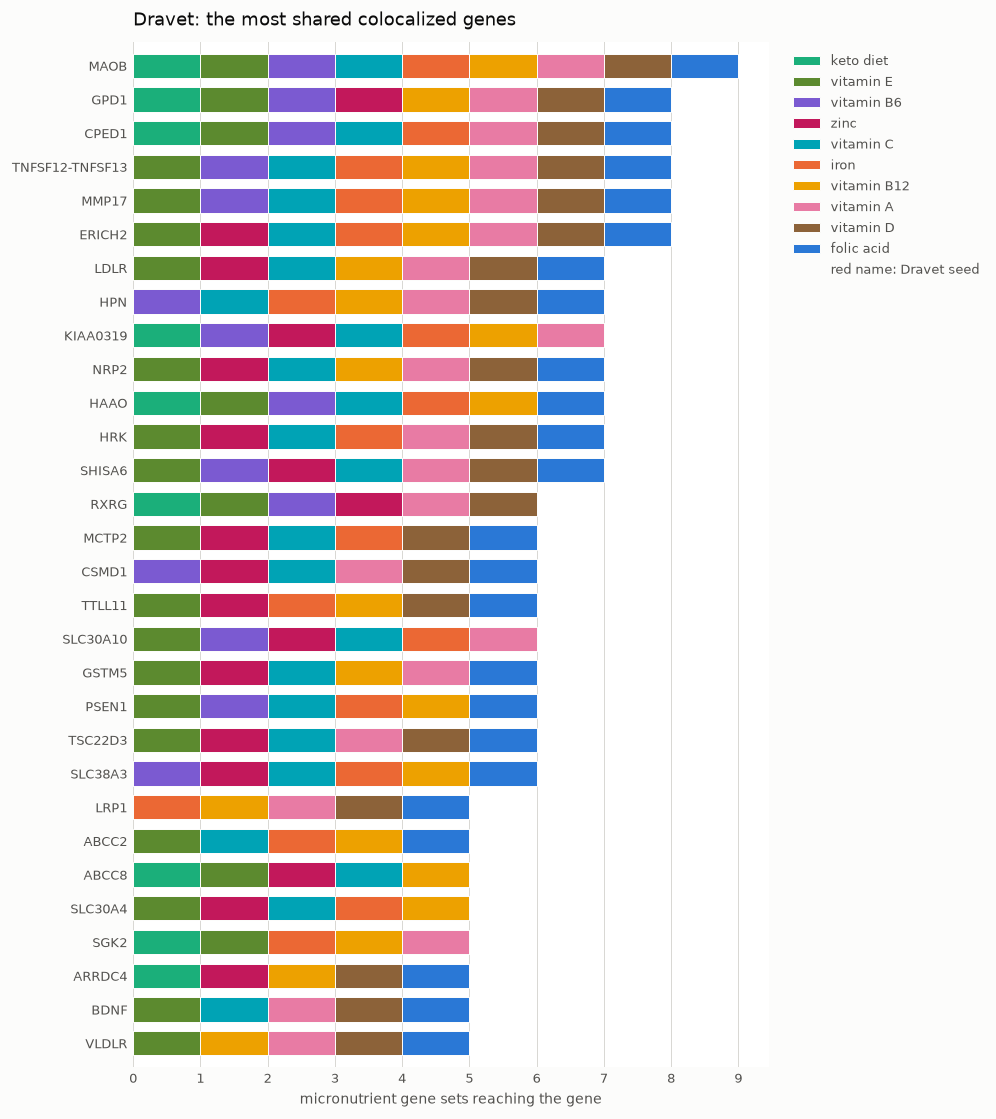

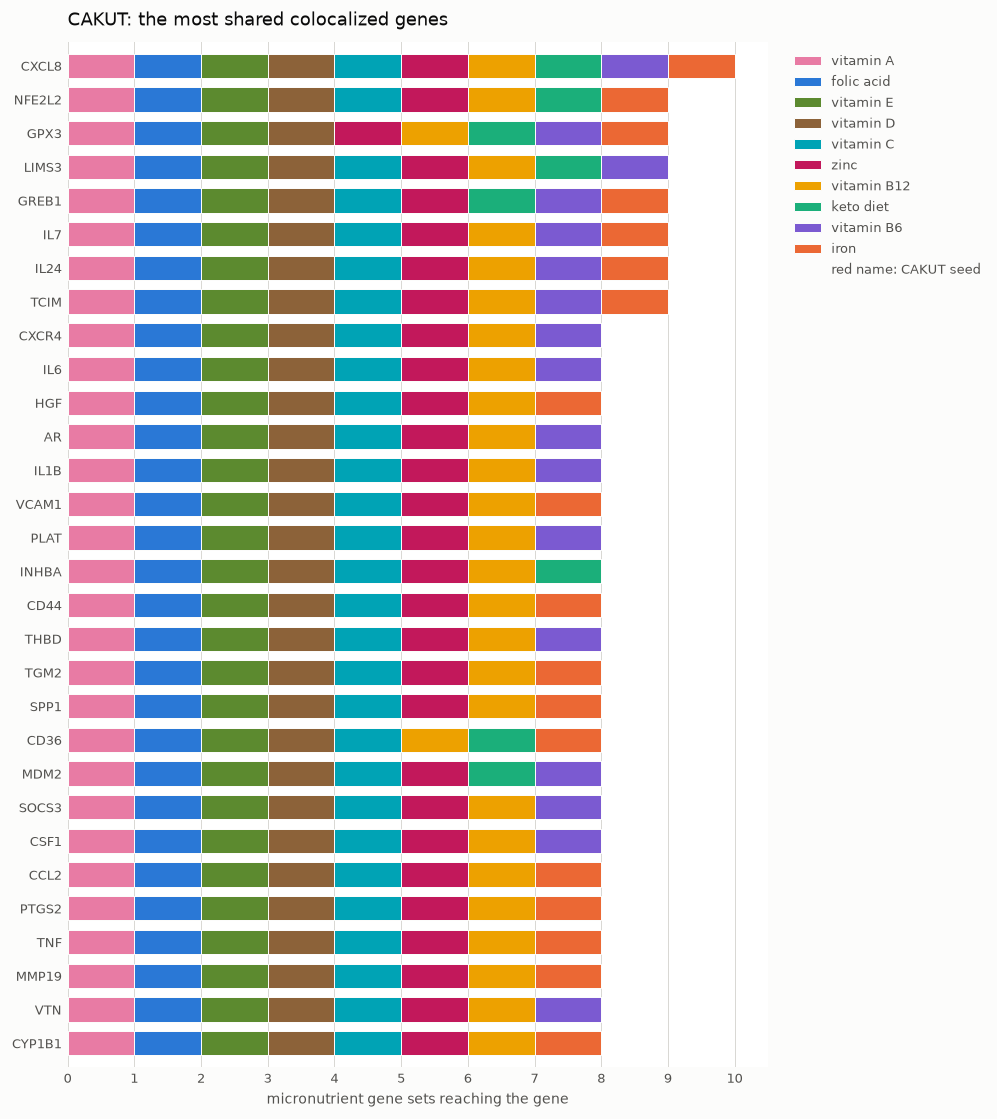

In [25]:
for disease, graph in graphs.items():
    fig = dkg.draw_shared_genes(
        graph, out_png=FIGURES / f"fig_{disease}_kg_shared_genes.png",
        top=30, min_nutrients=2,
    )
    plt.show()

### E2. Export

Each graph is written as GraphML for Cytoscape, and as node and edge tables.

In [26]:
for disease, (kg_edges, kg_annotation) in kg_inputs.items():
    core = dkg.build(kg_edges, kg_annotation, min_nutrients=2)
    for name, built in ((f"{disease}_coloc_kg", graphs[disease]),
                        (f"{disease}_coloc_kg_core", core)):
        print(dkg.export(built, name))

/home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/kg/dravet_coloc_kg.graphml
/home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/kg/dravet_coloc_kg_core.graphml


/home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/kg/cakut_coloc_kg.graphml
/home/alexandra/dravet/DS-micronutrients/results/micronutrient_coloc/kg/cakut_coloc_kg_core.graphml
